# Automated Marine Debris Detection

**COMP9444 · Project 014**

Tianyu Tang (z5708585)  
Sarang Rawat (z5630151)  
Shunhao Xu (z5697334)  
Roshni Roy (z5516075)  
Haorui Kang (z5464761)

We study object detection in underwater images using the TrashCan dataset. We compare longer
training, learning-rate decay, class-aware sampling, mask supervision and RT-DETR. Each section
explains the model or change, shows the results, and discusses what we learned.

### Contents
1. Research questions
2. Experimental setup
3. Dataset and evaluation
4. Models and fine-tuning
5. Paper reproduction and earlier experiments
6. Experiment overview
7. Training duration and learning rate
8. Class-aware sampling
9. Mask supervision
10. RT-DETR
11. Results and error analysis
12. Discussion and future work


# 1. Research Questions

Underwater detection must locate and classify objects despite low contrast, clutter, occlusion,
scale differences and a long-tailed label distribution. The 22-class task includes marine life and
ROV objects as well as debris: **overall AP is not a trash-only score**.

| Research question | Evidence required |
|---|---|
| Does additional optimization improve the baseline? | AP versus iteration, training losses, final versus best checkpoint |
| Does repetition help rare classes? | Image frequencies, repeat factors, per-class AP gains and regressions |
| Does mask supervision improve box detection? | Matched Faster/Mask comparison, mask AP, compute costs |
| How does a set-prediction detector behave differently? | RT-DETR results, objective and assignment mechanism, documented confounders |

**Ownership:** Detectron2 and Hugging Face implement the detector architectures. Our work is
dataset auditing, experiment design, training integration, controlled changes, metric verification,
visualization and analysis. Published architectures and pretrained weights are credited below.


# 2. Experimental Setup

The experiments used a Linux GPU environment, COCO-pretrained models and the official TrashCan
Instance split. The following table gives the training budgets and changes tested.

*Run All downloads the saved experiment records and displays their results; it does not repeat
training or inference. The experiment code is included for reference.*


In [ ]:
"""Download and display the frozen experiment; no local project or GPU required."""
import csv
import hashlib
import html
import io
import json
import os
from pathlib import Path
import urllib.request
import zipfile


def digest(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 * 1024**2), b''):
            h.update(block)
    return h.hexdigest()


def download(url, target, expected):
    target = Path(target)
    target.parent.mkdir(parents=True, exist_ok=True)
    if target.exists() and digest(target) == expected:
        print('Using verified cache:', target.name)
        return target
    temp = target.with_suffix(target.suffix + '.part')
    try:
        request = urllib.request.Request(url, headers={'User-Agent': 'MarineDebrisCourseNotebook/1.0'})
        with urllib.request.urlopen(request, timeout=120) as response, temp.open('wb') as stream:
            total = int(response.headers.get('Content-Length', 0))
            received = 0
            next_report = 25 * 1024**2
            while True:
                block = response.read(1024**2)
                if not block:
                    break
                stream.write(block); received += len(block)
                if received >= next_report:
                    print(f'{target.name}: {received / 1024**2:.0f} MB' +
                          (f' / {total / 1024**2:.0f} MB' if total else ''))
                    next_report += 25 * 1024**2
        if digest(temp) != expected:
            raise ValueError('Checksum mismatch for ' + target.name + '. Do not use this download.')
        temp.replace(target)
    except Exception as exc:
        temp.unlink(missing_ok=True)
        raise RuntimeError('Cannot retrieve ' + url +
            '. Check internet access, the public Release, and the configured repository. Rerun this cell.') from exc
    return target


def extract_verified(archive, target):
    target = Path(target).resolve()
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            path = (target / item.filename).resolve()
            if not path.is_relative_to(target) or (item.external_attr >> 16) & 0o170000 == 0o120000:
                raise ValueError('Unsafe archive entry: ' + item.filename)
        z.extractall(target)


def start(base_url, manifest, cache_dir, download_checkpoints=False):
    global RESULT_ROOT, SNAPSHOT
    from IPython.display import display, Markdown
    cache = Path(cache_dir).expanduser().resolve()
    result = manifest['results']
    archive = download(base_url + '/' + result['name'], cache / result['name'], result['sha256'])
    RESULT_ROOT = cache / ('results_' + result['sha256'][:12])
    extract_verified(archive, RESULT_ROOT)
    SNAPSHOT = json.loads((RESULT_ROOT / 'saved_outputs.json').read_text(encoding='utf-8'))
    records = json.loads((RESULT_ROOT / 'FILE_MANIFEST.json').read_text(encoding='utf-8'))
    for name, expected in records.items():
        if digest(RESULT_ROOT / name) != expected:
            raise ValueError('Extracted result file failed verification: ' + name)
    print('Experiment records loaded and verified.')
    if download_checkpoints:
        for item in manifest['checkpoints']:
            path = download(base_url + '/' + item['name'], cache / item['name'], item['sha256'])
            extract_verified(path, cache / 'checkpoints' / item['run'])
        print('Checkpoints downloaded and verified. They were not deserialized or executed.')
    return RESULT_ROOT


def show_saved_cell(cell_id):
    from IPython.display import display
    cell = SNAPSHOT[cell_id]
    for output in cell['outputs']:
        kind = output['output_type']
        if kind == 'stream':
            value = output.get('text', '')
            print(''.join(value) if isinstance(value, list) else value, end='')
        elif kind in ('display_data', 'execute_result'):
            data = {k: ''.join(v) if isinstance(v, list) else v for k, v in output['data'].items()}
            display(data, raw=True, metadata=output.get('metadata', {}))
        elif kind == 'error':
            raise RuntimeError('The archived cell contains an error: ' + cell_id)


def show_original_code(cell_id):
    from IPython.display import HTML, display
    source = SNAPSHOT[cell_id]['source']
    display(HTML('<details><summary>Experiment code</summary>'
                 '<pre>' + html.escape(source) + '</pre></details>'))


def verify_results():
    """Rebuild a summary from CSV and cross-check the independently recomputed AP audit."""
    from IPython.display import HTML, display
    path = RESULT_ROOT / 'records/comparison/final_comparison.csv'
    with path.open(encoding='utf-8', newline='') as f:
        rows = list(csv.DictReader(f))
    audits = json.loads((RESULT_ROOT / 'records/analysis/evaluation_audit.json').read_text())
    assert len(rows) == len(audits) == 5
    for r in rows:
        audit = next(a for a in audits if a['run'] == r['run'])
        assert abs(float(r['AP']) - audit['recomputed_AP']) < 1e-9
    body = ''.join('<tr><td>' + html.escape(r['model']) + '</td>' +
        ''.join(f'<td>{float(r[k]):.2f}</td>' for k in ['AP', 'AP50', 'AP75']) + '</tr>' for r in rows)
    display(HTML('<h3>Results summary</h3><table><tr><th>Model</th><th>AP</th>'
        '<th>AP50</th><th>AP75</th></tr>' + body + '</table>'))
    print('All five CSV results agree with the saved independent COCO AP audit.')
    print('AP is not classification accuracy.')


def export_outputs():
    """Return a portable index without changing the source project."""
    return str(RESULT_ROOT)

# Experiment resources
REPOSITORY = 'Pendrellvale/marine-debris-014'
RELEASE_TAG = 'results-v1'
DOWNLOAD_CHECKPOINTS = False  # True downloads all five final checkpoints (~3.9 GB); never needed to read results.
CACHE_DIRECTORY = Path(os.environ.get('MARINE_DEBRIS_CACHE_DIR', str(Path.home() / '.cache' / 'marine_debris_cloud')))
RELEASE_MANIFEST = {'schema': 1, 'suite': 'overnight_v1', 'source_notebook_sha256': '947da4e17f8015da837f6676d91c776b796d5094c32a4602ff11ca664cbd7c9b', 'results': {'name': 'marine_debris_results_v1.zip', 'sha256': '53b93454cce38007c2972da1a7980ede924b54874faf38e6b811875507e6349f', 'bytes': 86961535}, 'checkpoints': [{'run': '01_faster_constant', 'name': '01_faster_constant_checkpoint.zip', 'sha256': '96a0818a490267ec1b1b40e56508f85198f064cf1b1ae2a5e8fab5b75db45beb', 'bytes': 836082288, 'original_checkpoint_sha256': '1313aa4699d897b873a500544a14eb00c59db894b65d0c152cafc9027f4fd92f'}, {'run': '02_faster_decay', 'name': '02_faster_decay_checkpoint.zip', 'sha256': '4bb8bb71f8d5711060a77978131d3df4ac0dbe36cef5cd628fd8497c369c0bcd', 'bytes': 836082294, 'original_checkpoint_sha256': '813bbb1a76efd221929fcc281daa3b0424ca3aa7ad8d77ad17cae4a3db6caadc'}, {'run': '03_faster_balanced', 'name': '03_faster_balanced_checkpoint.zip', 'sha256': '84845f867713b71f9ba0937e12664c034d4f75d9f0354af5c02be5ccbd71fabb', 'bytes': 836082301, 'original_checkpoint_sha256': '5e9e57910eb9c99c617d3583c48410795beb0c0eb18a96f392a436c18b73dcf8'}, {'run': '04_mask_decay', 'name': '04_mask_decay_checkpoint.zip', 'sha256': '5da30ed740cc46c43a055f7215c9e4b1d02e6de3492ac8fd2a2c2bcd8106b2ff', 'bytes': 857119019, 'original_checkpoint_sha256': 'faa05b9d83bf8d25c35cdb52ccbe5610afb3985fe232a5816c869dbacd3385c6'}, {'run': '05_rtdetr', 'name': '05_rtdetr_checkpoint.zip', 'sha256': '145cb36388f0ad9579e71aaf21c3d2c5fc486d6e171a2af9aafcd41b0e9e6813', 'bytes': 514440606, 'original_checkpoint_sha256': '4ee21e0d6af99295aba0ead6292716a0042a0c96c0831fbdd6747fa8a3e35f46'}]}
BASE_URL = os.environ.get('MARINE_DEBRIS_ASSET_BASE_URL',
    f'https://github.com/{REPOSITORY}/releases/download/{RELEASE_TAG}')
if 'YOUR_GITHUB_USERNAME' in BASE_URL:
    raise RuntimeError('Owner setup is incomplete. Configure the GitHub repository and upload Release assets before submission.')
RESULTS_DIRECTORY = start(BASE_URL, RELEASE_MANIFEST, CACHE_DIRECTORY, DOWNLOAD_CHECKPOINTS)

verify_results()


In [ ]:
show_original_code('cell-003')

## 2.1 Predeclared experiments and controlled comparisons

| Run | Detector | Budget | Intervention |
|---|---|---|---|
| 01 | Faster R-CNN X101-FPN | 20k iterations × batch 2 | Constant LR after warmup |
| 02 | Faster R-CNN X101-FPN | Same | LR ×0.1 at 60% and 80% of budget |
| 03 | Faster R-CNN X101-FPN | Same | Run 02 + image-frequency repeat sampling |
| 04 | Mask R-CNN X101-FPN | Same | Run 02 + mask branch and mask annotations |
| 05 | RT-DETR R50vd | 12 epochs × batch 4 | Different detector family and training recipe |

The JSON configuration is authoritative if these defaults are edited. Runs 01–04 share COCO
Faster R-CNN initialization for common layers; Mask-specific layers start randomly.
CNN evaluations occur every 5k iterations. RT-DETR is evaluated every epoch.
Report **final checkpoints as the primary comparison** and validation-selected best checkpoints
as a separate secondary result. The selection rule is highest validation bounding-box AP.

RT-DETR is a **system comparison, not an isolated causal test of attention**: it differs in backbone,
pretraining, optimizer, image transformation and exposure. No factorial sweep is attempted.


# 3. Understanding the Dataset

TrashCan provides instance and material label versions. We use the official **Instance** version:
6,065 training images and 1,147 validation images with 22 classes.
The dataset audit reports these counts. The original photos and annotations are available from
[the official repository](https://conservancy.umn.edu/items/6dd6a960-c44a-4510-a679-efb8c82ebfb7).

### 3.1 Annotation format and preprocessing
Each object contains an image ID, category ID, box `[x, y, width, height]`, mask and area.
Detectron2 and RT-DETR require contiguous internal class indices; saved COCO predictions are mapped
back to original category IDs. Empty training images are excluded in both pipelines.
The RT-DETR loader clips/transforms boxes through its official image processor; horizontal flips
must transform the box coordinates together with the pixels.


,Dataset audit
train_images,6065
validation_images,1147
classes,22
train_objects,9540
validation_objects,2588
train_empty_images,129
shared_source_videos,113
note,Official split for benchmark development; not ...


,category,category_id,train_objects,train_images,val_objects,val_images
0,rov,1,2633,2197,684,524
1,plant,2,405,389,102,93
2,animal_fish,3,611,528,153,116
3,animal_starfish,4,262,92,136,42
4,animal_shells,5,188,104,61,35
5,animal_crab,6,246,152,63,34
6,animal_eel,7,259,182,84,77
7,animal_etc,8,170,165,65,56
8,trash_clothing,9,65,65,17,17
9,trash_pipe,10,114,114,42,42


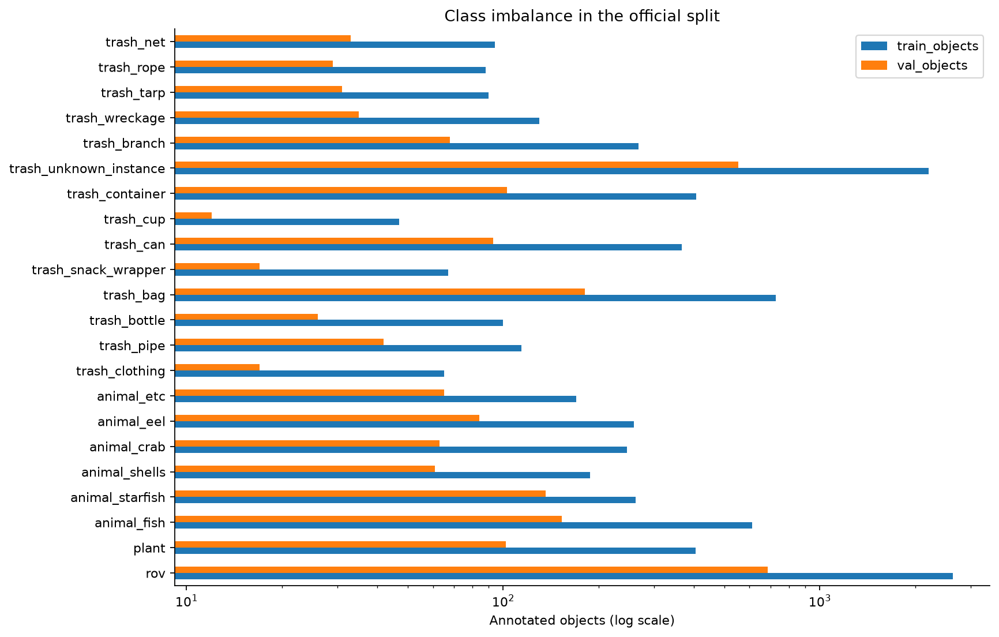

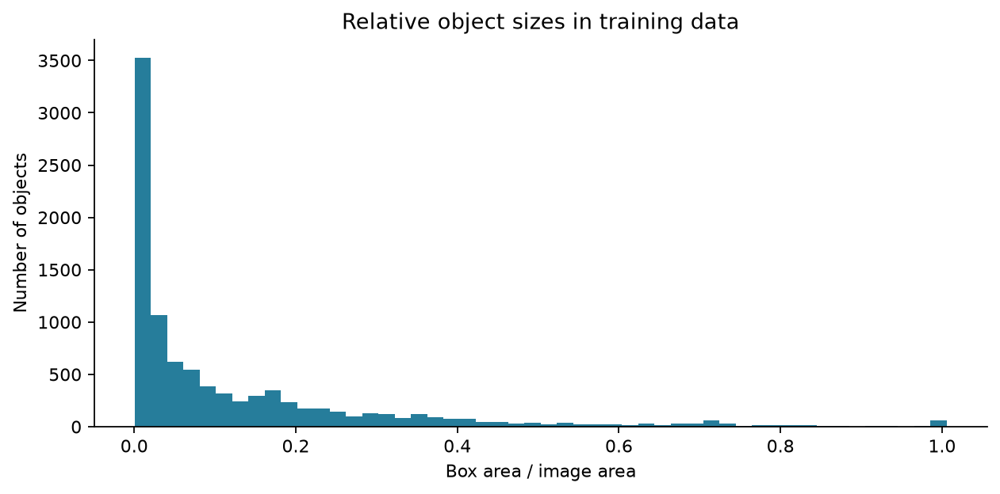

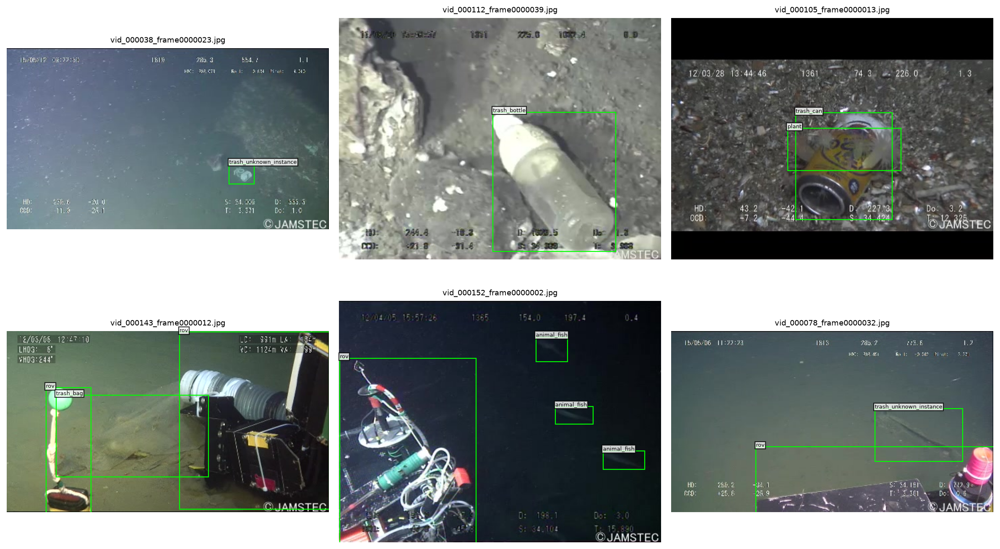

In [ ]:
show_original_code('cell-006')
show_saved_cell('cell-006')

### 3.2 What the class counts tell us

ROV objects account for 2,633 training annotations, and unknown debris for 2,203. Together they make up about half of the 9,540 objects. Cups have only 47 annotations and clothing has 65. This gives us a reason to try class-aware sampling. Object counts and image counts differ: 262 starfish appear in only 92 training images. Repeating one such image exposes the model to several related objects, rather than several independent scenes. We do not assume that every rare category is also a small-object category.
The object-size histogram uses relative box area, whereas COCO small/medium/large uses absolute
annotation area with its standard thresholds. These are different summaries.

### 3.3 Split integrity and the scope of generalization
There are no shared image filenames in the official split, but the previous audit identified shared
source videos. The live audit reports their count. Nearby frames can be correlated.
We retain the official split for benchmark continuity, **not** as proof of generalization to unseen
videos or oceans. Validation is repeatedly inspected for model development; there is no untouched
test score in this study. The historical custom test split cannot simply be reused because its images
may have appeared in the official training split.


## 3.4 Evaluation metrics

- **Box AP:** precision averaged over recall and IoU thresholds 0.50–0.95, then over classes.
- **AP50/AP75:** more permissive versus stricter localization requirements.
- **Mask AP:** segmentation overlap; report separately, never as box accuracy.
- **Precision/recall/F1 at confidence 0.50 and IoU 0.50:** an explicit deployment operating point.
- **Per-class and size-specific AP:** reveal differences hidden by an aggregate score.

Predictions are not thresholded at 0.50 before AP computation. COCO maxDets=100 is used.
**1 − AP is not an error rate.** Loss values from different architectures cannot be compared as
if they had the same scale. Timing includes validation preprocessing and metric computation unless
explicitly stated otherwise, so it must not be presented as pure model latency.


In [ ]:
show_original_code('cell-009')
show_saved_cell('cell-009')

def evaluate_predictions(rows, output, image_ids=None, task='bbox'):
    """COCO AP uses unthresholded predictions; fixed-point errors are separate."""
    output = Path(output)
    output.mkdir(parents=True, exist_ok=True)
    save_json(output / f'{task}_predictions.json', rows)
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(str(DATA / 'instances_val_trashcan.json'))
        if rows:
            dt = gt.loadRes(rows)
        else:
            dt = COCO()
            dt.dataset = dict(images=list(gt.imgs.values()), categories=list(gt.cats.values()), annotations=[])
            dt.createIndex()
        ev = COCOeval(gt, dt, task)
        if image_ids is not None:
            ev.params.imgIds = image_ids
        ev.evaluate()
        ev.accumulate()
        ev.summarize()
    names = ['AP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large',
             'AR1', 'AR10', 'AR100', 'AR_small', 'AR_medium', 'AR_large']
    metrics = {k: float(v * 100) if v >= 0 else None for k, v in zip(names, ev.stats)}
    per_class = []
    precision = ev.eval['precision']
    for k, cat in enumerate(ev.params.catIds):
        p = precision[:, :, k, 0, -1]
        valid = p[p >= 0]
        per_class.append(dict(category_id=int(cat), category=gt.cats[cat]['name'],
                              AP=float(valid.mean() * 100) if valid.size else None))
    save_json(output / f'{task}_metrics.json', metrics)
    save_json(output / f'{task}_per_class.json', per_class)
    np.savez_compressed(output / f'{task}_precision_recall.npz', precision=precision,
                        recall_thresholds=ev.params.recThrs, category_ids=ev.params.catIds)
    if task == 'bbox':
        counts = dict(TP=0, FP=0, FN=0)
        with contextlib.redirect_stdout(io.StringIO()):
            op = COCOeval(gt, dt, 'bbox')
            op.params.imgIds = ev.params.imgIds
            op.params.iouThrs = np.array([0.5])
            op.params.areaRng = [[0, 1e10]]
            op.params.areaRngLbl = ['all']
            op.params.maxDets = [100]
            op.evaluate()
        for e in op.evalImgs:
            if e is None:
                continue
            keep = np.array(e['dtScores']) >= 0.5
            matched = e['dtMatches'][0] > 0
            ignore = e['dtIgnore'][0]
            # Matching is confidence-ordered; lower-score detections cannot steal
            # matches from the retained prefix. Count retained GT matches only.
            counts['TP'] += int(np.sum(keep & matched & ~ignore))
            counts['FP'] += int(np.sum(keep & ~matched & ~ignore))
            eligible = int(np.sum(~np.asarray(e['gtIgnore'], dtype=bool)))
            counts['FN'] += eligible - int(np.sum(keep & matched & ~ignore))
        tp, fp, fn = (counts[k] for k in ('TP', 'FP', 'FN'))
        p, r = tp / max(tp + fp, 1), tp / max(tp + fn, 1)
        save_json(output / 'operating_point.json', dict(**counts, precision=p, recall=r,
                   F1=2*p*r/max(p+r, 1e-12), confidence=0.5, IoU=0.5,
                   note='Fixed operating point; 1-AP is not an error rate.'))
    return metrics

# 4. Understanding the Models and Fine-Tuning

## 4.1 Faster R-CNN: proposals followed by region classification
The CNN backbone extracts features. FPN combines feature maps at multiple scales. RPN predicts
objectness and box offsets for anchors. ROIAlign gathers aligned regional features; ROI heads
classify regions and refine boxes. NMS suppresses overlapping predictions at inference.

The training objective combines RPN objectness, RPN localization, ROI classification and ROI
localization losses. Inspect these components separately when total loss changes.

## 4.2 Mask R-CNN: additional pixel-level supervision
Mask R-CNN adds a per-region mask branch and mask loss. Shared features receive a richer training
signal, which could improve localization, but more supervision does not guarantee better box AP.
Our matched experiment keeps ROI sampling at 256 and uses the same detection initialization.
The new mask branch is random at initialization. Consequently, this experiment tests the addition
of a mask task under a fixed budget, not the best possible fully COCO-mask-pretrained system.

## 4.3 RT-DETR: hybrid features and Transformer set prediction
RT-DETR uses a CNN backbone, a hybrid encoder and a Transformer decoder with object queries.
During training, bipartite matching assigns predictions to ground-truth objects. Classification,
L1 box and generalized-IoU losses train matched predictions; auxiliary decoder and denoising
losses assist optimization. The query-based output does not use the standard RPN/ROI pipeline.
This is not a claim that the model is convolution-free.

## 4.4 Exactly what is fine-tuned?
CNN runs freeze the stem and early backbone stage (`FREEZE_AT=2`) and train later backbone stages,
FPN, RPN and task heads. Frozen normalization behavior comes from the resolved Detectron2 config.
RT-DETR uses a smaller backbone LR (1e-5) and a larger encoder/decoder/head LR (1e-4), AdamW,
gradient norm clipping at 0.1 and its pretrained normalization configuration.
Task-specific classification weights are reinitialized for 22 classes. Every run saves the names
and counts of trainable parameters and its weight-loading information.


In [ ]:
show_original_code('cell-011')
show_saved_cell('cell-011')

/mnt/h/unsw/2026 T3/COMP9444/marine_debris_014/paper_reproduction/environment/venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


class DebrisDataset(Dataset):
    def __init__(self, split, smoke=False):
        self.split = split
        self.data = json.loads((DATA/f'instances_{split}_trashcan.json').read_text())
        self.cats = sorted(self.data['categories'], key=lambda x: x['id'])
        self.to_label = {x['id']: i for i,x in enumerate(self.cats)}
        self.annotations = {}
        for a in self.data['annotations']:
            if a.get('iscrowd', 0) == 0 and a['bbox'][2] > 0 and a['bbox'][3] > 0:
                self.annotations.setdefault(a['image_id'], []).append(a)
        self.images = [x for x in self.data['images'] if split != 'train' or x['id'] in self.annotations]
        if smoke:
            self.images = self.images[:8]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, i):
        item = self.images[i]
        with Image.open(DATA/self.split/item['file_name']) as f:
            image = f.convert('RGB')
        anns = copy.deepcopy(self.annotations.get(item['id'], []))
        flip = self.split == 'train' and random.random() < .5
        if flip:
            image = ImageOps.mirror(image)
        for a in anns:
            a['category_id'] = self.to_label[a['category_id']]
            a.pop('segmentation', None)
            if flip:
                a['bbox'][0] = image.width - a['bbox'][0] - a['bbox'][2]
        return image, {'image_id': item['id'], 'annotations': anns}, item

class Collator:
    def __init__(self, processor):
        self.processor = processor

    def __call__(self, batch):
        images, annotations, meta = zip(*batch)
        inputs = self.processor(images=list(images), annotations=list(annotations), return_tensors='pt')
        return inputs, meta

## 4.5 Training implementation and separation of responsibilities

The following are the actual training functions used by the queue. They are displayed from source,
not separately maintained pseudocode. Paths, JSON writing and COCO metrics are shared in
`notebook_study/common.py`; plotting is in `reporting.py`; orchestration is in `runner.py`.
This keeps the notebook readable without hiding the model construction or optimization logic.


In [ ]:
show_original_code('cell-013')
show_saved_cell('cell-013')

/mnt/h/unsw/2026 T3/COMP9444/marine_debris_014/paper_reproduction/environment/detectron2/detectron2/model_zoo/model_zoo.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


def main(name, smoke=False):
    c = config(smoke)
    seed_all(c['seed'])
    out = run_dir(c, name)
    out.mkdir(parents=True, exist_ok=True)
    setup_logger(output=str(out / 'training.log'))
    mask = name == '04_mask_decay'
    for split in ('train', 'val'):
        full = f'study_{split}'
        register_coco_instances(full, {}, str(DATA / f'instances_{split}_trashcan.json'), str(DATA / split))
        if smoke:
            samples = DatasetCatalog.get(full)[:8]
            DatasetCatalog.register(full + '_smoke', lambda x=samples: x)
            meta = MetadataCatalog.get(full).as_dict()
            for k in ('name', 'json_file'):
                meta.pop(k, None)
            MetadataCatalog.get(full + '_smoke').set(**meta)
    train_name = 'study_train' + ('_smoke' if smoke else '')
    val_name = 'study_val' + ('_smoke' if smoke else '')
    cfg = get_cfg()
    zoo = ('COCO-InstanceSegmentation/mask_rcnn_X_101_32x8d_FPN_3x.yaml' if mask else
           'COCO-Detection/faster_rcnn_X_101_32x8d_FPN_3x.yaml')
    cfg.merge_from_file(model_zoo.get_config_file(zoo))
    # Both detectors start from the SAME COCO detection weights. Mask-only layers
    # are randomly initialized; record this instead of comparing unequal pretraining.
    weights = ROOT / 'paper_reproduction/pretrained_weights/coco_faster_rcnn_x101.pkl'
    cfg.MODEL.WEIGHTS = str(weights)
    cfg.MODEL.ROI_HEADS.NUM_CLASSES = 22
    cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 256
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.0
    cfg.MODEL.BACKBONE.FREEZE_AT = 2
    cfg.DATASETS.TRAIN, cfg.DATASETS.TEST = (train_name,), (val_name,)
    cfg.DATALOADER.NUM_WORKERS = c['workers']
    cfg.SOLVER.IMS_PER_BATCH = c['d2_batch_size']
    cfg.SOLVER.BASE_LR = c['d2_lr']
    cfg.SOLVER.MAX_ITER = c['d2_iterations']
    cfg.SOLVER.STEPS = (() if name == '01_faster_constant' else
                        (int(c['d2_iterations'] * .6), int(c['d2_iterations'] * .8)))
    cfg.SOLVER.GAMMA = 0.1
    cfg.SOLVER.WARMUP_ITERS = min(1000, c['d2_iterations'] // 5)
    cfg.SOLVER.CHECKPOINT_PERIOD = c['d2_eval_period']
    cfg.TEST.EVAL_PERIOD = c['d2_eval_period']
    cfg.FLOAT32_PRECISION = 'highest'
    cfg.SEED = c['seed']
    cfg.OUTPUT_DIR = str(out)
    cfg.freeze()
    (out / 'config.yaml').write_text(cfg.dump())
    info = provenance(c, name, 'Mask R-CNN X101-FPN' if mask else 'Faster R-CNN X101-FPN')
    info.update(initialization=str(weights), initialization_sha256=sha256(weights),
                mask_initialization='random mask branch, common COCO detection initialization' if mask else None,
                freeze_at=2, precision='FP32', expected_image_presentations=c['d2_iterations']*c['d2_batch_size'])
    started = time.perf_counter()
    eval_history = []
    old_history = out / 'evaluation_history.json'
    if old_history.exists():
        eval_history = json.loads(old_history.read_text())
    best = max((x['AP'] for x in eval_history), default=-1)

    class Trainer(DefaultTrainer):
        @classmethod
        def build_train_loader(cls, cfg):
            if name != '03_faster_balanced':
                return build_detection_train_loader(cfg)
            dataset = get_detection_dataset_dicts(cfg.DATASETS.TRAIN)
            factors = RepeatFactorTrainingSampler.repeat_factors_from_category_frequency(dataset, c['repeat_threshold'])
            save_json(out / 'sampling.json', dict(threshold=c['repeat_threshold'],
                      factors=factors.tolist(), mean_factor=float(factors.mean()),
                      note='Repeat factors use image frequency; co-occurring common classes are also repeated.'))
            return build_detection_train_loader(cfg, dataset=dataset,
                    sampler=RepeatFactorTrainingSampler(factors, seed=c['seed']))

        def build_hooks(self):
            base = [h for h in super().build_hooks() if not isinstance(h, hooks.EvalHook)]
            base.insert(-1, hooks.EvalHook(c['d2_eval_period'], self.evaluate_saved))


In [ ]:
show_original_code('cell-014')
show_saved_cell('cell-014')

def main(smoke=False):
    c = config(smoke)
    seed_all(c['seed'])
    out = run_dir(c, '05_rtdetr')
    out.mkdir(parents=True, exist_ok=True)
    train, val = DebrisDataset('train', smoke), DebrisDataset('val', smoke)
    labels = {i:x['name'] for i,x in enumerate(train.cats)}
    processor = RTDetrImageProcessor.from_pretrained(c['rtdetr_model'], revision=c['rtdetr_revision'],
                  size={'height': c['rtdetr_image_size'], 'width': c['rtdetr_image_size']})
    model, loading = RTDetrForObjectDetection.from_pretrained(c['rtdetr_model'], revision=c['rtdetr_revision'],
                    id2label=labels, label2id={v:k for k,v in labels.items()},
                    ignore_mismatched_sizes=True, output_loading_info=True)
    save_json(out/'weight_loading.json', loading)
    # Only task-specific classification and denoising embeddings may change shape.
    allowed = ('class_embed', 'enc_score_head', 'denoising_class_embed')
    for item in loading.get('mismatched_keys', []):
        key = item[0] if isinstance(item, (tuple, list)) else item
        if not any(x in key for x in allowed):
            raise RuntimeError(f'Unexpected pretrained shape mismatch: {key}')
    if loading.get('missing_keys') or loading.get('unexpected_keys') or loading.get('error_msgs'):
        raise RuntimeError(f'Unexpected pretrained loading differences: {loading}')
    model = model.cuda()
    backbone, rest = [], []
    for name,p in model.named_parameters():
        if p.requires_grad:
            (backbone if 'backbone' in name else rest).append(p)
    optimizer = torch.optim.AdamW([{'params':backbone, 'lr':c['rtdetr_backbone_lr'], 'name':'backbone'},
                                   {'params':rest, 'lr':c['rtdetr_lr'], 'name':'encoder_decoder_heads'}], weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.MultiStepLR(optimizer, milestones=[max(1,int(c['rtdetr_epochs']*.75))], gamma=.1)
    train_loader = DataLoader(train, batch_size=c['rtdetr_batch_size'], shuffle=True,
                              num_workers=c['workers'], collate_fn=Collator(processor))
    val_loader = DataLoader(val, batch_size=c['rtdetr_batch_size'], shuffle=False,
                            num_workers=c['workers'], collate_fn=Collator(processor))
    info = provenance(c, '05_rtdetr', 'RT-DETR R50vd')
    info.update(total_parameters=sum(p.numel() for p in model.parameters()),
                trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
                trainable_names=[n for n,p in model.named_parameters() if p.requires_grad],
                initialization=c['rtdetr_model'], revision=c['rtdetr_revision'], precision='FP32',
                train_images=len(train), resize='640x640 stretch; differs from aspect-preserving CNN pipeline',
                optimizer='AdamW; backbone LR 1e-5, remaining LR 1e-4; weight decay 1e-4; clip norm .1',
                expected_image_presentations=len(train)*c['rtdetr_epochs'])
    save_json(out/'provenance.json', info)
    processor.save_pretrained(out/'processor')
    model.config.save_pretrained(out/'model_config')
    start_epoch, best, history = 0, -1, []
    checkpoint = out/'last.pt'
    if checkpoint.exists():
        saved = torch.load(checkpoint, map_location='cpu', weights_only=False)
        model.load_state_dict(saved['model'])
        optimizer.load_state_dict(saved['optimizer'])
        scheduler.load_state_dict(saved['scheduler'])
        start_epoch, best, history = saved['epoch'], saved['best'], saved['history']
        random.setstate(saved['random_state'])
        torch.set_rng_state(saved['torch_rng'])
        torch.cuda.set_rng_state_all(saved['cuda_rng'])
        del saved
    started = time.perf_counter()
    torch.cuda.reset_peak_memory_stats()
    for epoch in range(start_epoch, c['rtdetr_epochs']):
        model.train()
        loss_sum, samples, loss_parts = 0., 0, {}
        ep_start = time.perf_counter()
        lrs = [g['lr'] for g in optimizer.par

# 5. Reproduction Context and Existing Results

Author-checkpoint evaluation and independent training answer different questions. Our earlier
paper-aligned Faster R-CNN training reached about 33.80 box AP; the same weights with TTA reached
about 35.69. Missing historical author settings prevent certification of exact reproduction.
The earlier three-epoch Torchvision experiments used a different split and belong to exploration,
not the controlled comparison below.

The new CNN constant-LR run provides its own 10k checkpoint for training-duration comparisons.
It is preferable to comparing unrelated runs: it shares the new run's data path and evaluation
thresholds. Historical values are context only.


In [ ]:
show_original_code('cell-016')
show_saved_cell('cell-016')

,run,AP,AP50,AP75
0,01_author_faster_rcnn_10000,42.562242,64.154631,48.716543
1,02_author_mask_rcnn_15000,46.055990,70.898711,55.125421
2,03_author_mask_rcnn_40000,54.689000,76.713075,63.974788
3,04_retrained_faster_rcnn_10000,33.799227,54.253440,38.188754
4,05_faster_rcnn_tta,35.686806,56.966789,40.662712


## 5.1 Imported Track A: RetinaNet and the one-stage alternative

**Evidence provenance:** the following completed experiments were supplied in
`Marine_Debris_014_English_2026-11-11`. A bounded copy, including selected raw predictions,
source code, configurations and figures, is preserved in `notebook_study/historical/track_a/`.
`IMPORT_MANIFEST.json` records source paths and SHA-256 hashes. This notebook does not retrain
RetinaNet or claim these imported runs were executed by its new queue.

| Protocol | Historical Track A | New main study |
|---|---|---|
| Split | 5,194 train / 1,025 validation / 993 test | 6,065 train / 1,147 validation |
| Video separation | Video-disjoint custom split | Official split, shared source videos |
| CNN backbone | ResNet-50 FPN | ResNeXt-101 FPN; RT-DETR uses R50vd |
| Purpose | Historical architecture, duration and sampling cases | New controlled CNN experiments and Transformer comparison |

**Never merge these AP values into one leaderboard.** The historical test result belongs only
to its frozen Track-A model and is not a valid test result for our official-split models.

### How RetinaNet differs
RetinaNet predicts class scores and box offsets densely over FPN features, without a separate RPN
and ROI classification stage. Focal loss reduces the contribution of easy classified examples:
`FL(p_t) = -alpha_t * (1-p_t)^gamma * log(p_t)`.
Here p_t is the probability of the correct binary outcome. Larger gamma suppresses easy examples
more strongly; gamma=0 recovers alpha-weighted binary cross-entropy.

This addresses dense foreground/background imbalance. It does **not** automatically balance
rare foreground categories or create new visual diversity. Image repetition is a separate intervention.
See [the RetinaNet paper](https://arxiv.org/abs/1708.02002) and
[Torchvision's implementation](https://github.com/pytorch/vision/blob/main/torchvision/ops/focal_loss.py).


"""One-stage alternative: COCO-initialized RetinaNet with ResNet-50-FPN."""
from torchvision.models.detection import retinanet_resnet50_fpn
from torchvision.models.detection.retinanet import RetinaNetClassificationHead

from .common import load_pretrained, prepare_backbone


def build(config, num_classes, initialize=False):
    model = retinanet_resnet50_fpn(
        weights=None,
        weights_backbone=None,
        num_classes=91,
        min_size=config['min_size'],
        max_size=config['max_size'],
        score_thresh=.001,
        detections_per_img=100,
    )
    prepare_backbone(model)
    if initialize:
        load_pretrained(
            model,
            'retinanet_resnet50_fpn_coco-eeacb38b.pth',
            'eeacb38b',
        )
    model.head.classification_head = RetinaNetClassificationHead(
        model.backbone.out_channels,
        model.anchor_generator.num_anchors_per_location()[0],
        num_classes,
    )
    return model

<Figure size 840x480 with 1 Axes>

,model,detector_family,best_epoch,box_AP_percent,box_AP50_percent,box_AP75_percent,parameters_million,median_latency_ms,total_training_validation_seconds
0,Faster R-CNN,two-stage region proposal,2,9.466,15.556,10.083,41.407,17.015,303.897
1,Mask R-CNN,two-stage region proposal,2,9.953,16.621,10.738,44.035,60.762,476.745
2,RetinaNet,one-stage dense,3,4.359,7.977,4.056,32.604,31.139,593.294


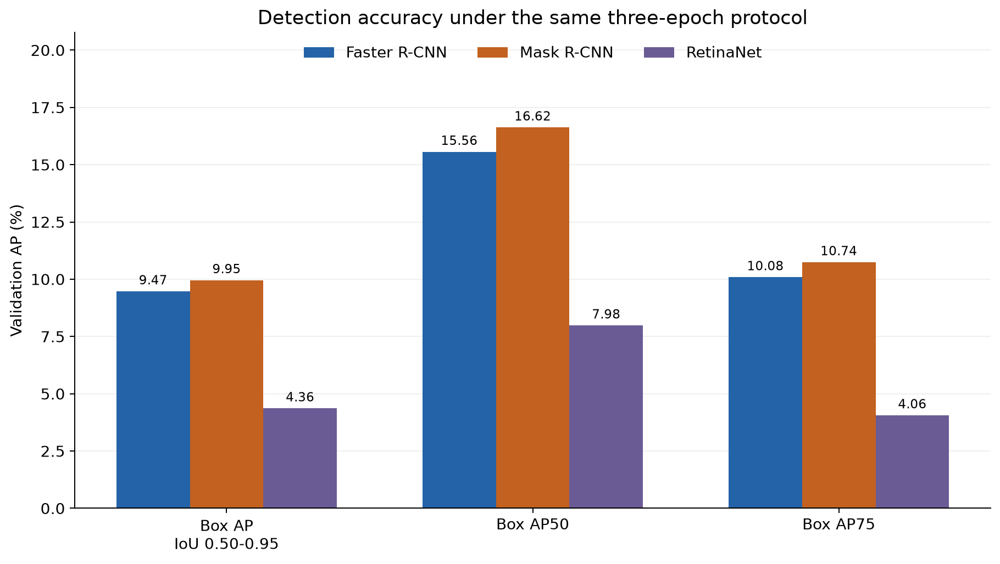

In [ ]:
show_original_code('cell-018')
show_saved_cell('cell-018')

### Interpretation of the imported three-epoch result
RetinaNet achieved 4.36% validation box AP, versus 9.47% for Faster R-CNN and 9.95% for Mask R-CNN
under the historical three-epoch recipe. This is a short-budget comparison, not evidence that
one-stage detection is intrinsically inferior. Its validation trajectory was still improving.
Matching an optimizer and epoch budget does not guarantee each architecture receives its best recipe.

## 5.2 Imported duration and balance experiments
The two extended RetinaNet branches share the same first three epochs and resume from the same
checkpoint. Epochs 4–12 use random versus image-frequency weighted sampling, with the same number
of samples per epoch. The historical repeat threshold is 0.05 with a cap of 5; the new Detectron2
experiment uses a different implementation and threshold, which must not be silently equated.


,run,sampling,best_epoch,box_AP_percent,box_AP50_percent,box_AP75_percent,total_training_validation_seconds
0,3 epochs,random,3,4.359,7.977,4.056,593.294
1,"12 epochs, random",random,12,8.089,12.994,8.982,1754.570
2,"12 epochs, balanced",repeat_factor,9,7.324,11.929,7.693,2123.217


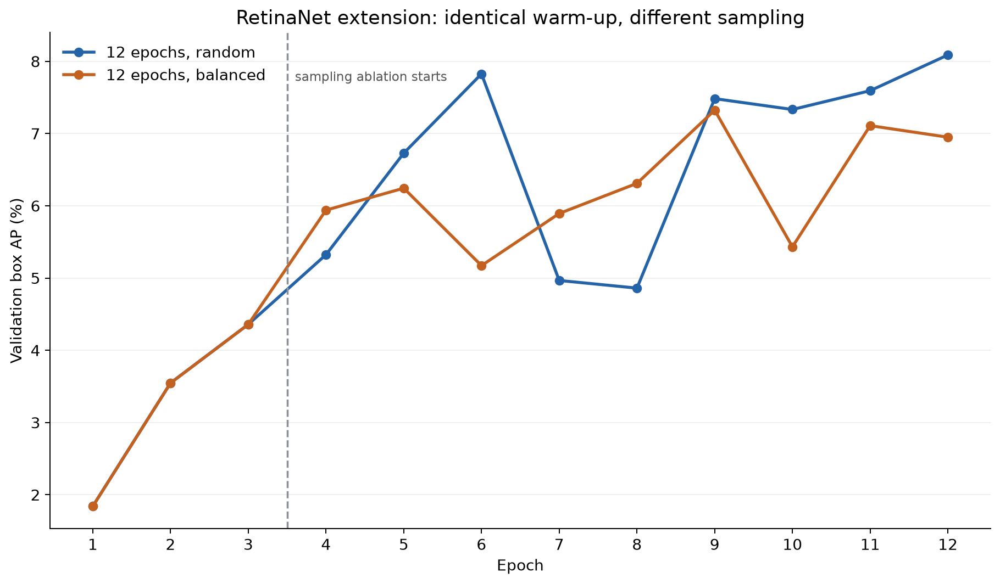

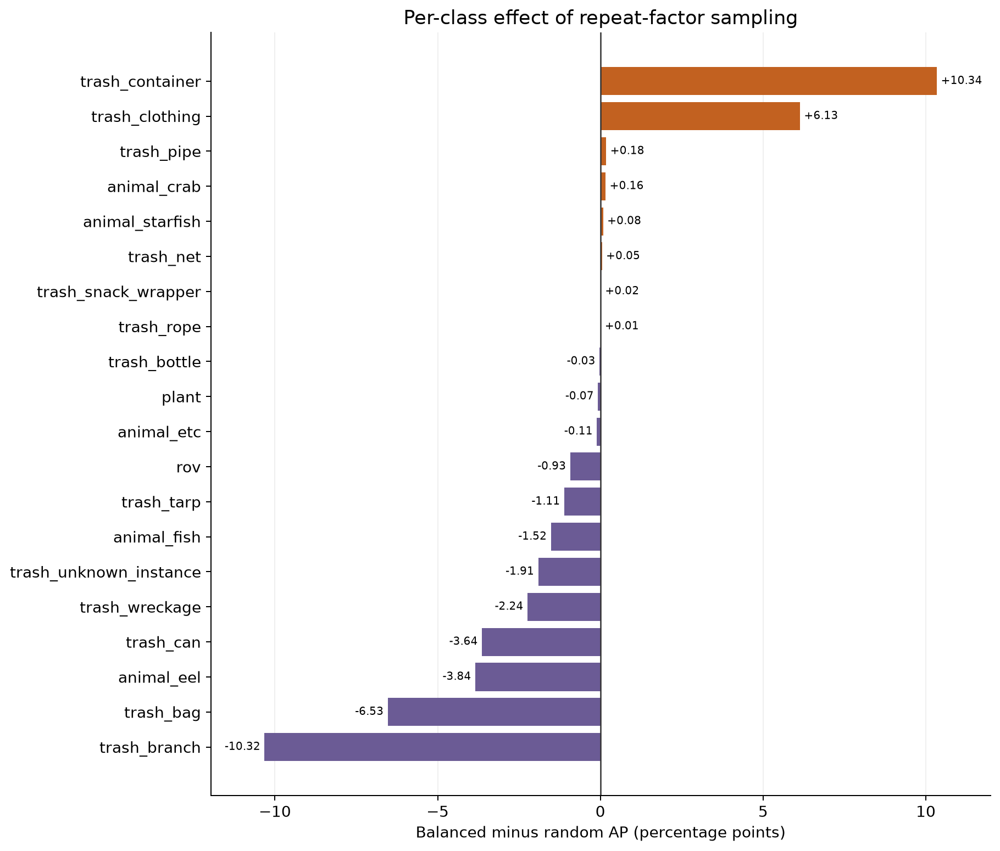

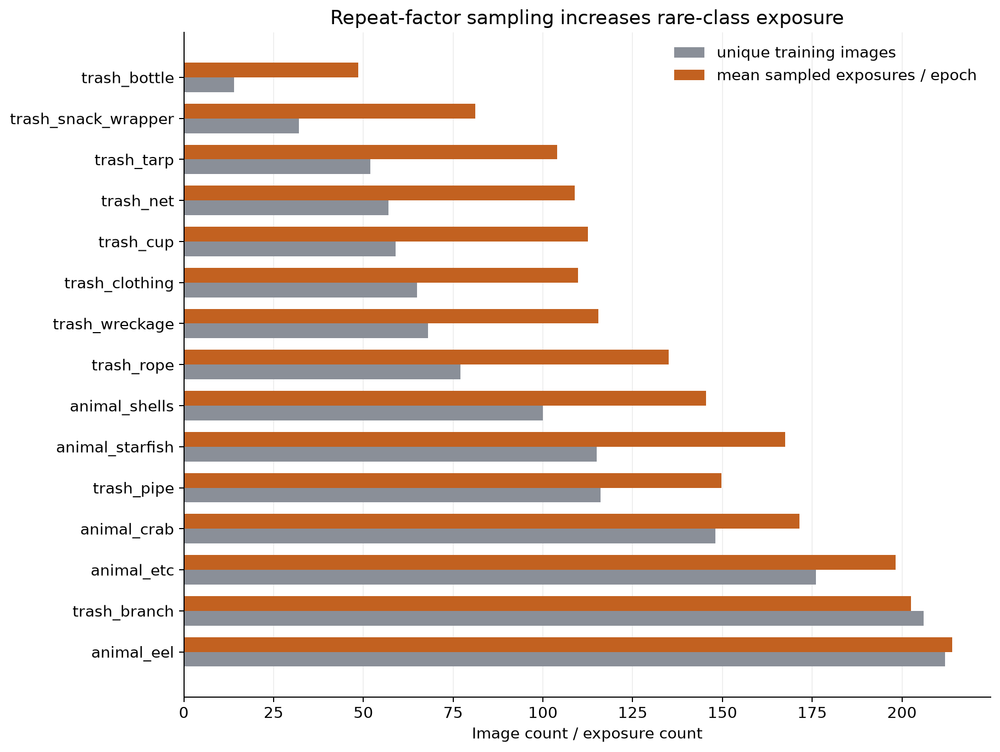

In [ ]:
show_original_code('cell-020')
show_saved_cell('cell-020')

### Interpretation of the imported ablation
The selected random-sampling model improved from 4.36% to 8.09% AP with longer training.
The balanced branch reached 7.32% overall AP, while the reported rare-class macro AP improved
from approximately 0.92% to 1.33%. Thus better exposure can help a subset of categories while
reducing the overall metric. Undefined validation classes are excluded, not replaced by zero.
Best epochs differ (12 versus 9); these are validation-selected comparisons under a common
maximum budget. A single seed does not establish a statistically reliable advantage.

The supplied records also report 5.39% test AP for the frozen random-sampling RetinaNet.
We preserve that historical result and do not reopen its test split for new tuning.


# 6. Experiment Overview

We completed five training runs. The table below summarizes their final and validation-selected
checkpoints. The following sections examine each change separately.


In [ ]:
show_original_code('cell-023')
show_saved_cell('cell-023')

Analysis mode: no training started.


,model,selection,AP,AP50,AP75,precision_at_05,recall_at_05
0,Faster: constant LR,final,40.456,61.816,44.929,0.708,0.717
1,Faster: constant LR,best,40.456,61.816,44.929,0.708,0.717
2,Faster: LR decay,final,43.923,64.116,48.449,0.727,0.723
3,Faster: LR decay,best,43.923,64.116,48.449,0.727,0.723
4,Faster: repeat sampling,final,43.767,63.625,48.154,0.720,0.719
5,Faster: repeat sampling,best,43.767,63.625,48.154,0.720,0.719
6,Mask: LR decay,final,43.960,63.688,49.235,0.713,0.723
7,Mask: LR decay,best,43.960,63.688,49.235,0.713,0.723
8,RT-DETR,final,45.752,61.891,50.853,0.000,0.000
9,RT-DETR,best,45.752,61.891,50.853,0.000,0.000


In [ ]:
show_original_code('cell-024')

# 7. Training Duration and Learning-Rate Schedule

## 7.1 Hypothesis: the short baseline has not exhausted useful optimization
Run 01 keeps LR fixed after warmup. Compare its 10k and 20k evaluations, and inspect whether
loss reductions correspond to validation improvements. Lower training loss alone is insufficient
evidence of better generalization. Report extra training cost alongside the gain.


,Value
model,Faster R-CNN X101-FPN
total_parameters,104487230
trainable_parameters,104062078
peak_gpu_memory_gb,6.200754
expected_image_presentations,40000


,selection,AP,AP50,AP75,AP_small,AP_medium,AP_large,precision_at_05,recall_at_05
0,final,40.456,61.816,44.929,36.071,46.162,58.74,0.708,0.717
1,best,40.456,61.816,44.929,36.071,46.162,58.74,0.708,0.717


,step,AP,evaluation_seconds,elapsed_seconds,path
0,5000,25.252706,75.192895,1206.957818,evaluations/iter_005000
1,10000,35.019435,74.595065,2412.340029,evaluations/iter_010000
2,15000,36.034687,74.275990,3621.578887,evaluations/iter_015000
3,20000,40.455932,75.421578,4915.826946,evaluations/iter_020000


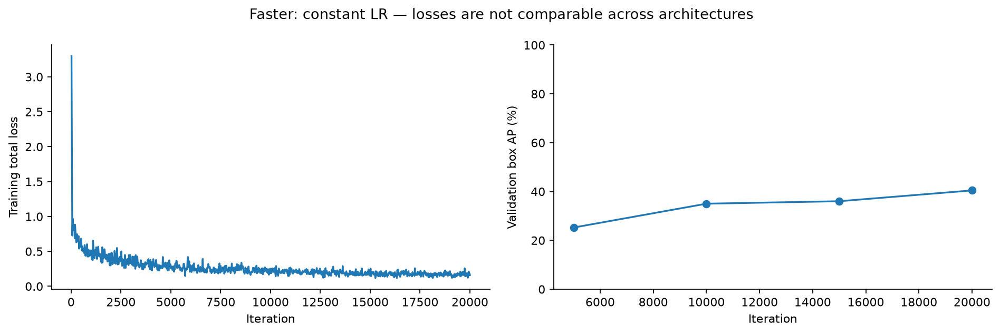

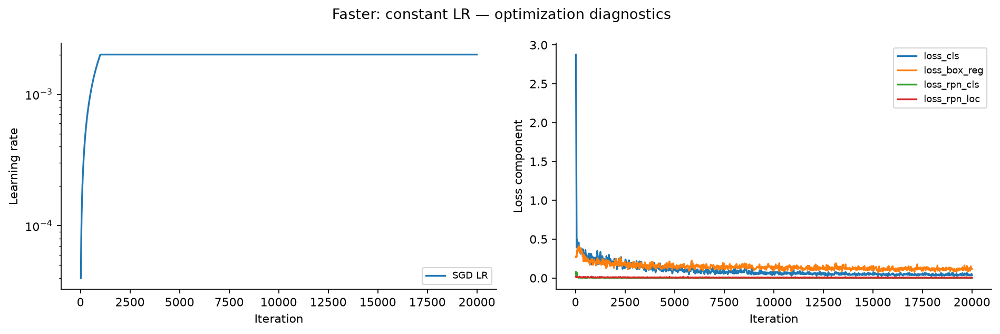

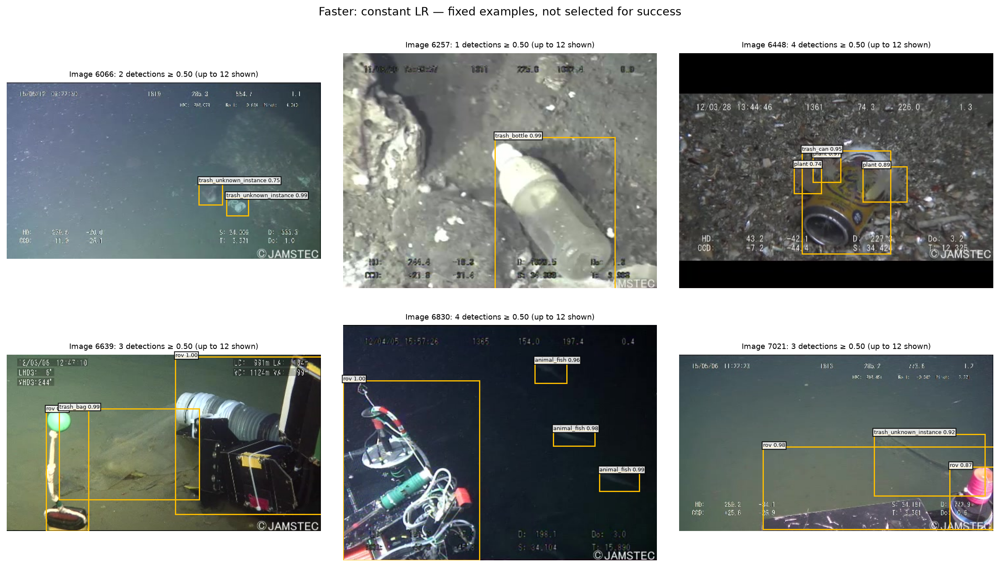

In [ ]:
show_original_code('cell-026')
show_saved_cell('cell-026')

### 7.1 What happened when we trained for longer?
The constant-LR model reached **35.02 AP at 10,000 iterations** and **40.46 AP at 20,000**.
That is a gain of **5.44 percentage points**. We doubled the number of training image presentations
from 20,000 to 40,000. The extra training was useful in this run, so the earlier short experiment
was not a good estimate of what the detector could achieve.

AP still increased between 15,000 and 20,000 iterations. We do not see a clear validation decline
at the recorded checkpoints. This does not prove that overfitting is absent, or that another 20,000
iterations would give the same gain. We would check a validation curve before extending the budget.
The final model is weaker on small objects (36.07 AP) than large ones (58.74 AP). More training
alone has not removed that gap. Object size and class composition may both contribute.

**Record correction:** the training hook labelled one final evaluation as iteration 20,001.
The recovery check then evaluated the same final model as iteration 20,000. Their AP values agree.
We show one final point at 20,000. The original files and selection paths are kept for checking.

## 7.2 Testing smaller updates near the end
Run 02 uses the same budget as Run 01. The learning rate falls from 0.002 to 0.0002 at 12,000
iterations, then to 0.00002 at 16,000. Smaller updates may help refine weights once the model has
learned useful features. Reducing the rate too early could also slow learning.



,Value
model,Faster R-CNN X101-FPN
total_parameters,104487230
trainable_parameters,104062078
peak_gpu_memory_gb,6.200773
expected_image_presentations,40000


,selection,AP,AP50,AP75,AP_small,AP_medium,AP_large,precision_at_05,recall_at_05
2,final,43.923,64.116,48.449,42.196,48.246,59.908,0.727,0.723
3,best,43.923,64.116,48.449,42.196,48.246,59.908,0.727,0.723


,step,AP,evaluation_seconds,elapsed_seconds,path
0,5000,26.958046,75.318494,1212.525328,evaluations/iter_005000
1,10000,33.901473,75.290085,2422.009354,evaluations/iter_010000
2,15000,43.076286,75.678273,3633.733808,evaluations/iter_015000
3,20000,43.923036,74.775914,4929.731729,evaluations/iter_020000


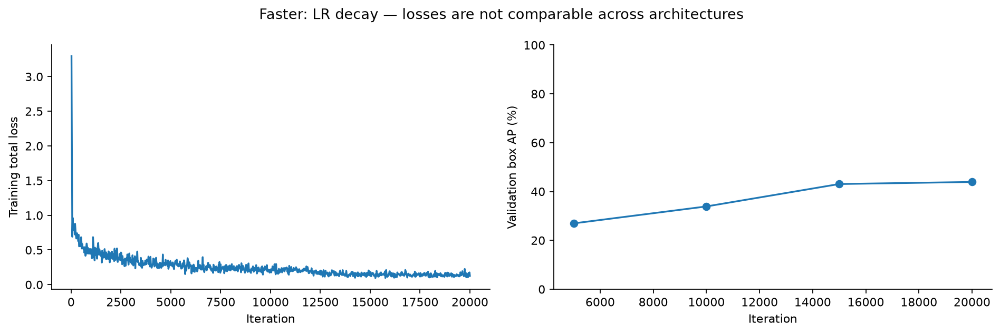

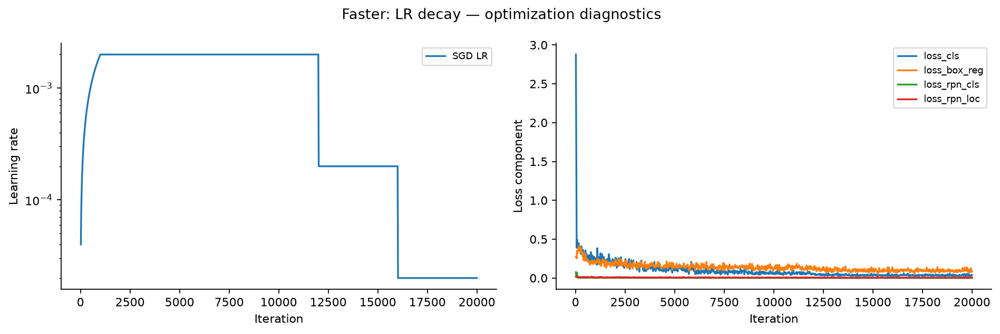

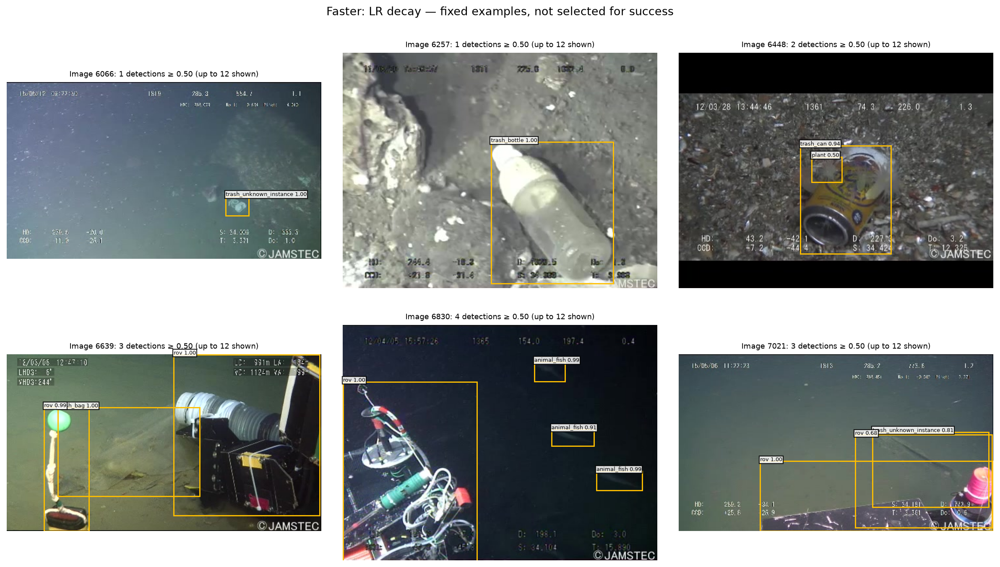

In [ ]:
show_original_code('cell-028')
show_saved_cell('cell-028')

### 7.2 What did the learning-rate schedule change?
Final AP increased from **40.46 to 43.92**, a gain of **3.47 points** with the same training budget.
AP50 increased from 61.82 to 64.12, and AP75 from 44.93 to 48.45. Small-object AP rose from
36.07 to 42.20. Among our matched CNN changes, this was the largest overall improvement.

The decay run reached 33.90 AP at 10,000 iterations and 43.08 at 15,000. This is consistent with
useful refinement after the first rate reduction. However, the two runs already differ before
12,000 iterations, even though their planned rates match at that stage. A shared seed does not
guarantee identical GPU execution or training paths. We therefore describe this as evidence from
one comparison, rather than a precise measurement of the schedule's effect in every run.

For the remaining CNN experiments, we use the decay model as our reference. A repeat with several
seeds would tell us whether the improvement is reliable.



# 8. Class-Aware Sampling

## 8.1 Fine-tuning point: the training sampler, not the validation distribution
Run 03 uses repeat factors based on category image frequency. For category frequency f and
threshold t, the factor is max(1, sqrt(t/f)); an image takes the largest factor of its categories.
The default t=0.03 must be interpreted using the measured image frequencies.
The optimizer, LR schedule and number of sampled images match Run 02.

This is not a perfectly balanced dataset. Repetition changes exposure, not unique information;
co-occurring frequent categories may also receive more exposure. Repeated rare images may overfit.


,Value
model,Faster R-CNN X101-FPN
total_parameters,104487230
trainable_parameters,104062078
peak_gpu_memory_gb,6.203994
expected_image_presentations,40000


,selection,AP,AP50,AP75,AP_small,AP_medium,AP_large,precision_at_05,recall_at_05
4,final,43.767,63.625,48.154,41.703,48.886,64.607,0.72,0.719
5,best,43.767,63.625,48.154,41.703,48.886,64.607,0.72,0.719


,step,AP,evaluation_seconds,elapsed_seconds,path
0,5000,26.618392,74.509667,1206.944956,evaluations/iter_005000
1,10000,35.303745,74.365229,2413.195349,evaluations/iter_010000
2,15000,43.336729,74.983493,3621.145110,evaluations/iter_015000
3,20000,43.766684,75.359880,4917.156213,evaluations/iter_020000


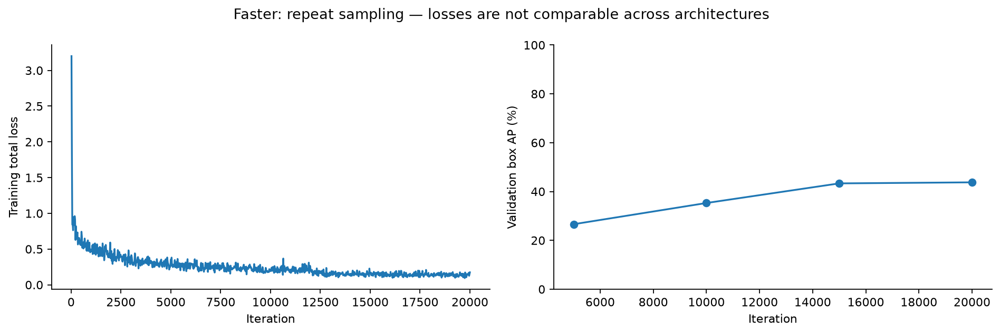

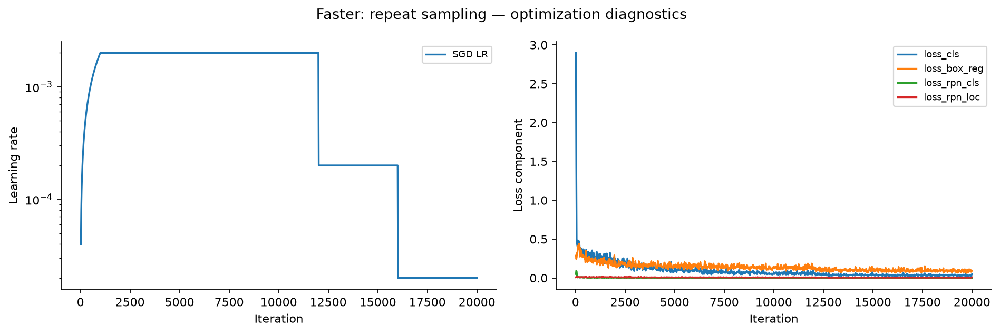

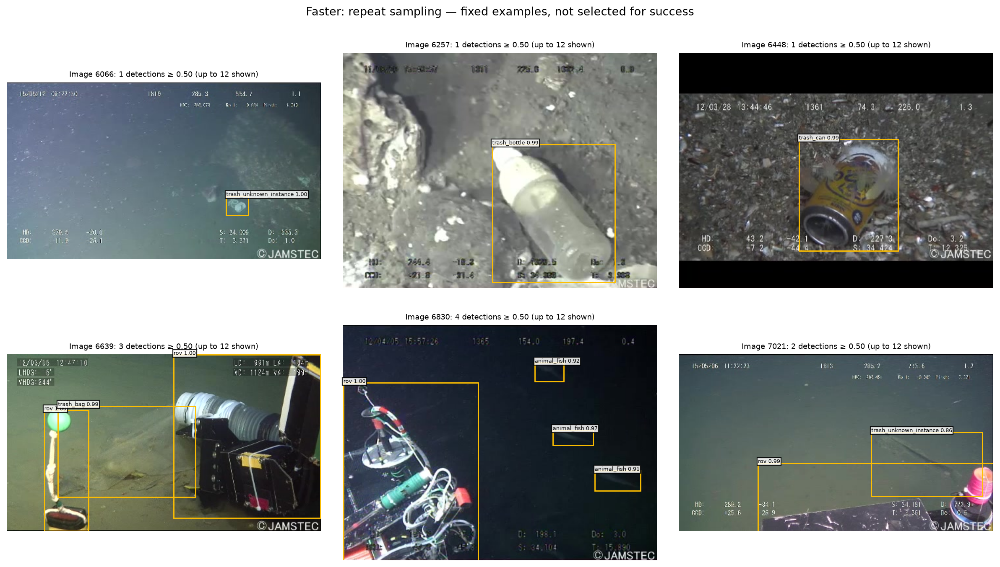

,Value
threshold,0.03
mean_factor,1.065289
note,Repeat factors use image frequency; co-occurri...


<Figure size 840x360 with 1 Axes>

In [ ]:
show_original_code('cell-031')
show_saved_cell('cell-031')

### 8.2 Did repeating rare-class images help?
Overall AP changed from **43.92 to 43.77**: a small drop of **0.16 points**. This setting did not
improve the main clean-validation score. It also did not create new examples. It only made some
existing images appear more often during training.

The class-level results are more useful than the average alone. Net AP increased from **39.43 to
47.72** (+8.29 points), and clothing from **24.42 to 29.04** (+4.62). Pipe AP fell from **64.09 to
56.49** (-7.61), while bottle AP fell by 4.19 points. Both gains and losses occur among uncommon
classes, so we cannot say that all rare classes benefited. Per-class AP is also noisy when there
are few validation examples: clothing has only 17 objects, and cups have 12.

An image can contain several classes. Repeating it may increase exposure to common objects too.
Some repeated images may be too similar to add much information. These are possible explanations,
not causes established by this experiment. Later, the corruption test shows a benefit from this
sampler even though its clean AP is slightly lower. That makes it worth discussing, rather than
discarding it as a failed experiment.

A useful next test would compare a smaller repeat threshold or targeted augmentation at the same
budget. We should decide the rare-class group from training frequency before inspecting results.



# 9. Mask Supervision and Architecture

## 9.1 Fine-tuning point: an additional mask head and loss
Run 04 compares with Run 02 using the same backbone, detector initialization, ROI batch size,
training budget and LR schedule. The mask branch uses pixel-level annotations, so this comparison
changes both the architecture and the supervision available to the model.


,Value
model,Mask R-CNN X101-FPN
total_parameters,107115604
trainable_parameters,106690452
peak_gpu_memory_gb,6.233189
expected_image_presentations,40000


,selection,AP,AP50,AP75,AP_small,AP_medium,AP_large,precision_at_05,recall_at_05
6,final,43.96,63.688,49.235,42.322,47.216,64.19,0.713,0.723
7,best,43.96,63.688,49.235,42.322,47.216,64.19,0.713,0.723


,step,AP,evaluation_seconds,elapsed_seconds,path
0,5000,23.084927,102.467944,1285.731281,evaluations/iter_005000
1,10000,34.725809,99.722429,2561.830018,evaluations/iter_010000
2,15000,43.029216,103.675809,3877.050157,evaluations/iter_015000
3,20000,43.960396,99.586540,5283.078220,evaluations/iter_020000


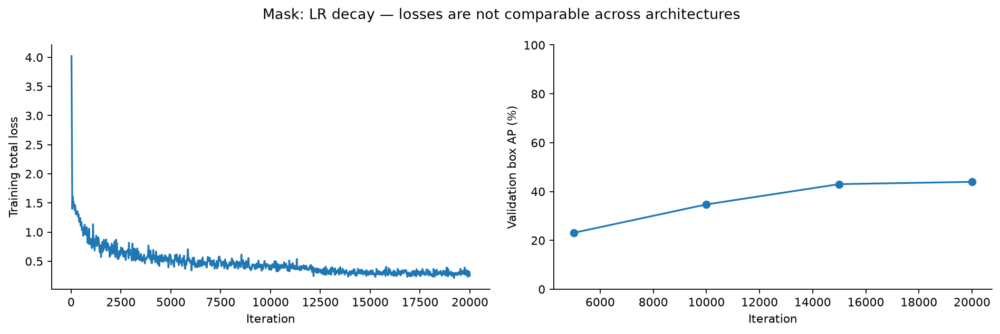

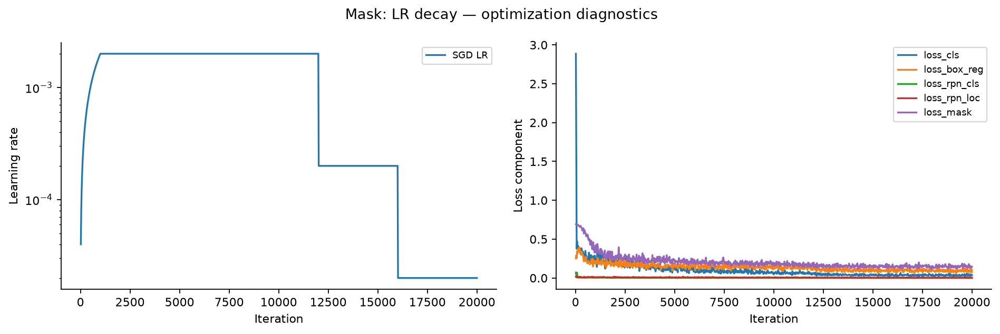

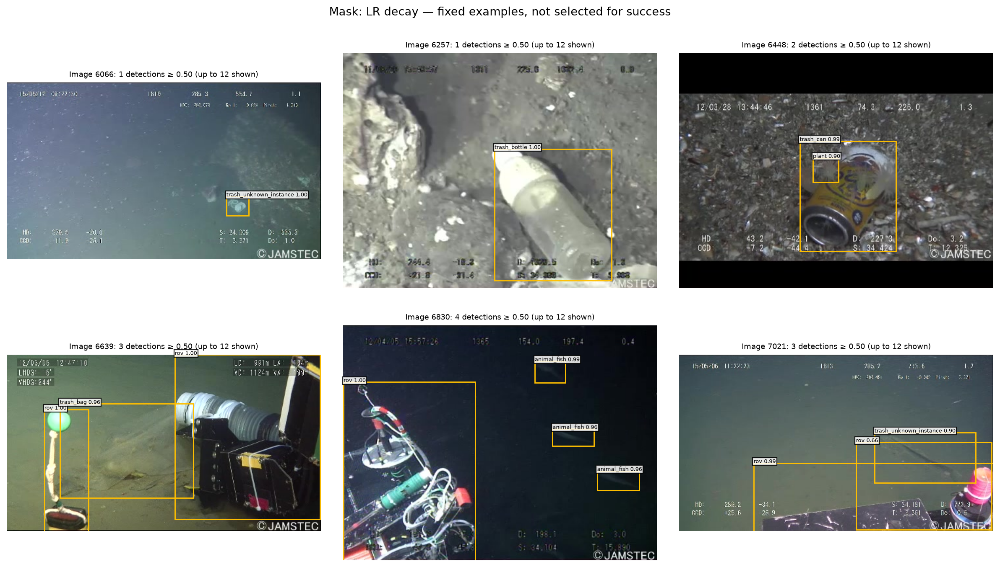

### Segmentation is evaluated separately from bounding boxes

,selection,AP,mask_AP
6,final,43.96,31.374
7,best,43.96,31.374


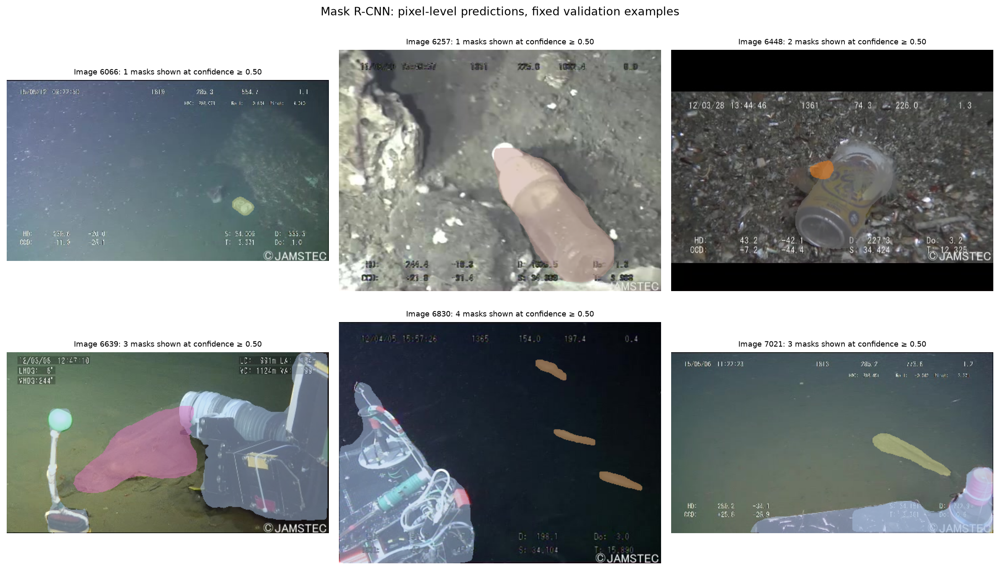

In [ ]:
show_original_code('cell-034')
show_saved_cell('cell-034')

### 9.2 Did the extra mask task improve detection?
Mask R-CNN reached **43.96 box AP**, compared with **43.92** for the matched Faster R-CNN.
The difference is only **0.04 points**. We treat their overall detection performance as very close;
one run cannot support a claim that the mask branch improves box AP reliably.

AP75 increased from 48.45 to **49.24**, while AP50 decreased from 64.12 to **63.69**. The stricter
overlap result is consistent with slightly better localization for some predictions, but these
aggregate metrics do not identify the exact objects responsible. Large-object AP increased from
59.91 to 64.19; medium-object AP fell from 48.25 to 47.22.

The separate **mask AP is 31.37**. This measures pixel overlap, so it is not directly comparable
with box AP and is not a 31.37% classification accuracy. The mask examples show what the extra
output looks like. Masks could be useful for estimating the visible shape or area of debris.
They do not directly estimate physical area without camera and distance information.

The mask model has about **107.12 million parameters**, compared with 104.49 million for Faster
R-CNN. It also needs mask labels and an extra loss. Our mask head started randomly, while the shared
detector layers used the same pretrained initialization. For a box-only task, these results do not
show a clear reason to choose the extra branch. For a segmentation task, its output is useful in
a way the box-only model cannot provide.



# 10. Transformer-Based Detection with RT-DETR

## 10.1 Fine-tuning points and optimization
The COCO-pretrained checkpoint is pinned to a model revision. Its classification and denoising
label embeddings are adapted to the 22-class vocabulary; the loader audits shape mismatches.
The backbone uses a smaller learning rate than the encoder, decoder and heads.
Training uses full precision, AdamW, horizontal flipping and a 640×640 image processor.
The simple recipe omits many sophisticated official training augmentations and is not an RT-DETR
paper reproduction. No claim of optimal RT-DETR performance is intended.

## 10.2 Why this is a different detector mechanism
Compare queries and matching with anchors, proposals and ROI assignment. Explain how unique
target assignment discourages duplicate predictions, and why small objects or limited training
can remain difficult. RT-DETR retains CNN feature extraction; the contrast is not “CNN absent”.


,Value
model,RT-DETR R50vd
total_parameters,42772182
trainable_parameters,42772182
peak_gpu_memory_gb,4.251912
expected_image_presentations,71232


,selection,AP,AP50,AP75,AP_small,AP_medium,AP_large,precision_at_05,recall_at_05
8,final,45.752,61.891,50.853,41.147,52.061,67.394,0.0,0.0
9,best,45.752,61.891,50.853,41.147,52.061,67.394,0.0,0.0


,epoch,loss,AP,train_seconds,evaluation_seconds,backbone_lr,other_lr,loss_components,path
0,1,25.135440,25.314505,271.608565,36.112663,0.000010,0.00010,"{'loss_vfl': 2.37101583524213, 'loss_bbox': 0....",evaluations/epoch_001
1,2,17.222640,31.488381,262.479168,34.946409,0.000010,0.00010,"{'loss_vfl': 1.8466867934661413, 'loss_bbox': ...",evaluations/epoch_002
2,3,15.034154,36.050318,264.676332,35.526504,0.000010,0.00010,"{'loss_vfl': 1.746022665717531, 'loss_bbox': 0...",evaluations/epoch_003
3,4,13.757740,38.383368,263.299263,35.901217,0.000010,0.00010,"{'loss_vfl': 1.687347142643363, 'loss_bbox': 0...",evaluations/epoch_004
4,5,13.044428,40.022211,263.500400,35.721248,0.000010,0.00010,"{'loss_vfl': 1.6400396885335284, 'loss_bbox': ...",evaluations/epoch_005
5,6,12.427923,40.936251,261.494356,35.553942,0.000010,0.00010,"{'loss_vfl': 1.622028442285453, 'loss_bbox': 0...",evaluations/epoch_006
6,7,12.017882,42.331109,268.086887,35.977136,0.000010,0.00010,"{'loss_vfl': 1.6174414340617522, 'loss_bbox': ...",evaluations/epoch_007
7,8,11.650354,42.311050,265.923738,35.613471,0.000010,0.00010,"{'loss_vfl': 1.6359098195387025, 'loss_bbox': ...",evaluations/epoch_008
8,9,11.430392,43.496753,263.017512,35.498673,0.000010,0.00010,"{'loss_vfl': 1.6285165731476323, 'loss_bbox': ...",evaluations/epoch_009
9,10,10.248629,45.292098,261.322668,35.508983,0.000001,0.00001,"{'loss_vfl': 1.618232155786049, 'loss_bbox': 0...",evaluations/epoch_010


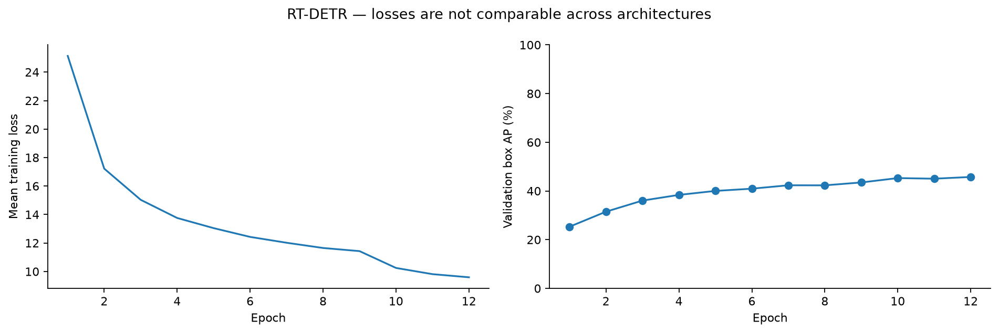

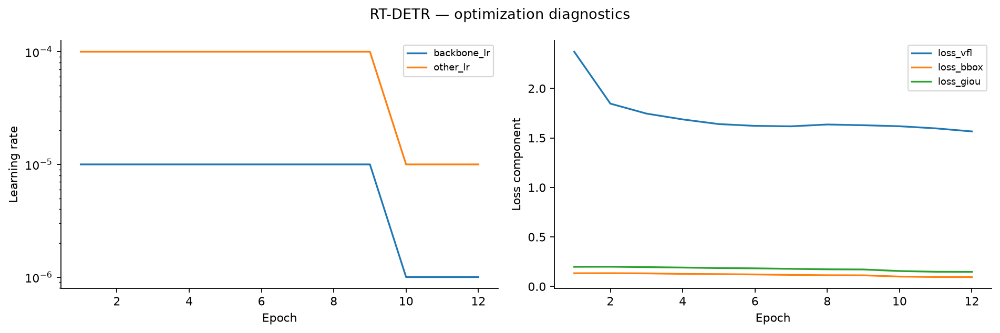

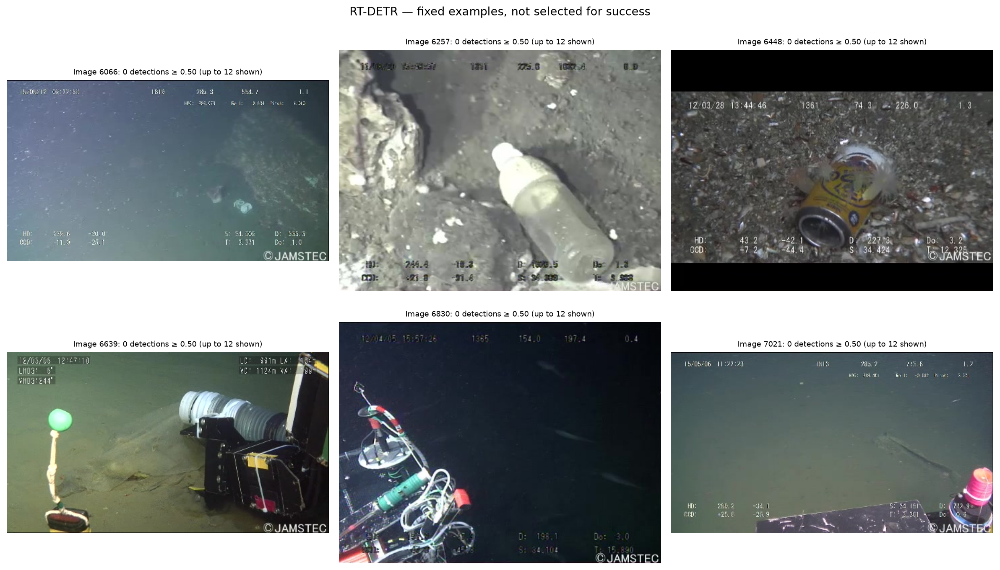

In [ ]:
show_original_code('cell-037')
show_saved_cell('cell-037')

### 10.3 What changed with RT-DETR?
RT-DETR reached **45.75 AP**, the highest final AP in this study. It is **1.79 points** above Mask
R-CNN. AP increased from 25.31 after epoch 1 to 45.75 after epoch 12, with small fluctuations near
the end. There is still some improvement late in training, but this is not enough to predict the
benefit of a longer run.

Its AP75 is **50.85**, above the CNN results, while AP50 is **61.89**, below the decay Faster
R-CNN's 64.12. RT-DETR is therefore not better under every overlap requirement. Its medium-object
AP is 52.06 and large-object AP is 67.39. Small-object AP is 41.15, slightly below the strongest
CNN result of 42.32. Attention does not automatically solve small-object detection.

This model has **42.77 million parameters**, fewer than half the CNN models. However, it saw
**71,232 training image presentations**, compared with 40,000 for each CNN. It also used a different
backbone, pretrained checkpoint, optimizer and 640-square resize. We compare these complete systems;
we cannot assign the AP gain to the Transformer decoder alone.

### 10.4 Why is recall zero at confidence 0.50?
All saved RT-DETR scores are below 0.50; the largest is about **0.330**. Filtering at 0.50 therefore
removes every box. Recall is zero, and precision is mathematically undefined when no boxes remain.
Our evaluator records precision as zero by convention. AP uses ranked predictions without this
cutoff, so a useful AP and an empty 0.50-threshold display can occur together.

We checked the training and evaluation code. The image processor applies one sigmoid to logits,
the saved model uses the corresponding focal-loss setting, and predictions are mapped back to the
dataset's category IDs. The installed varifocal loss uses matched box IoU as a positive score target,
rather than always using 1. This helps explain why its score meaning differs from a region classifier.
It does **not** fully explain why every score is this low. Limited training and score calibration
remain possible issues; we have not established their cause.

We also replayed validation image 6066 from the saved final checkpoint. The processor's scores
matched a direct single sigmoid of the logits. The largest difference from the saved top-100 scores
was about 0.000091, with a different batch size. This supports the score-conversion check on that
image; it does not prove that the model is well calibrated on the full dataset.

We keep the original scores. We do not rescale them to make the 0.50 result look better.
The next diagnostic section checks threshold sensitivity using the same saved boxes.



## 10.5 Checking the confidence threshold
These diagnostics reuse saved predictions; no model is retrained. We recompute standard COCO AP
for every final model and check it against the saved metric. The threshold curves count class-correct
matches at IoU 0.50. Precision, recall and F1 here are micro averages across objects, whereas COCO AP
averages over classes. They should not be interpreted as the same metric.


,model,count,median,p90,p99,maximum
0,Faster: constant LR,114700,0.0012,0.0210,0.9728,0.9994
1,Faster: LR decay,114700,0.0003,0.0105,0.9826,0.9995
2,Faster: repeat sampling,114700,0.0003,0.0094,0.9857,0.9996
3,Mask: LR decay,114700,0.0004,0.0123,0.9827,0.9995
4,RT-DETR,114700,0.0091,0.0219,0.2047,0.3300


,run,saved_AP,recomputed_AP,raw_history_rows,displayed_history_rows
0,01_faster_constant,40.4559,40.4559,5,4
1,02_faster_decay,43.9230,43.9230,5,4
2,03_faster_balanced,43.7667,43.7667,5,4
3,04_mask_decay,43.9604,43.9604,5,4
4,05_rtdetr,45.7521,45.7521,12,12


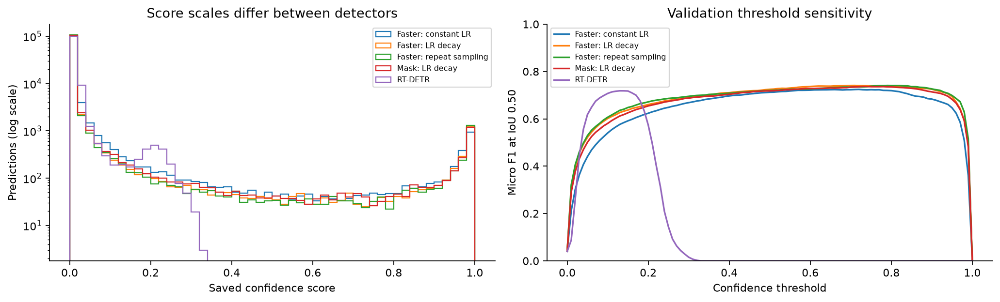

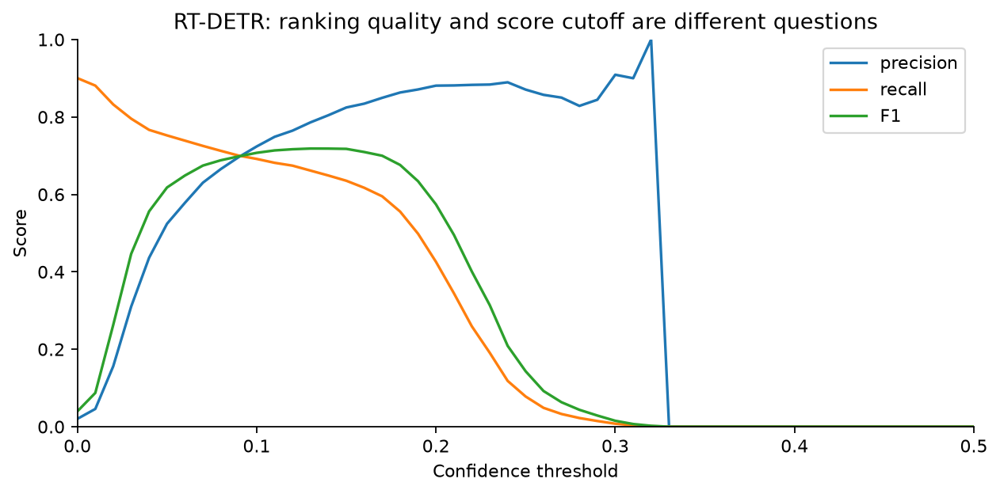

### Example cutoffs for RT-DETR (validation only)

,threshold,precision,recall,F1,TP,FP,FN,precision_defined
409,0.05,0.5242,0.7523,0.6179,1947,1767,641,True
414,0.10,0.7238,0.6917,0.7074,1790,683,798,True
419,0.15,0.8245,0.6352,0.7176,1644,350,944,True
424,0.20,0.8809,0.4258,0.5741,1102,149,1486,True
429,0.25,0.8707,0.0781,0.1433,202,30,2386,True
434,0.30,0.9091,0.0077,0.0153,20,2,2568,True
454,0.50,0.0000,0.0000,0.0000,0,0,2588,False


### Exploratory best F1 on the validation threshold grid

,model,threshold,precision,recall,F1
72,Faster: constant LR,0.72,0.7913,0.6681,0.7245
172,Faster: LR decay,0.71,0.8048,0.6866,0.7410
281,Faster: repeat sampling,0.79,0.8213,0.6750,0.7410
376,Mask: LR decay,0.73,0.8069,0.6781,0.7369
417,RT-DETR,0.13,0.7860,0.6615,0.7184


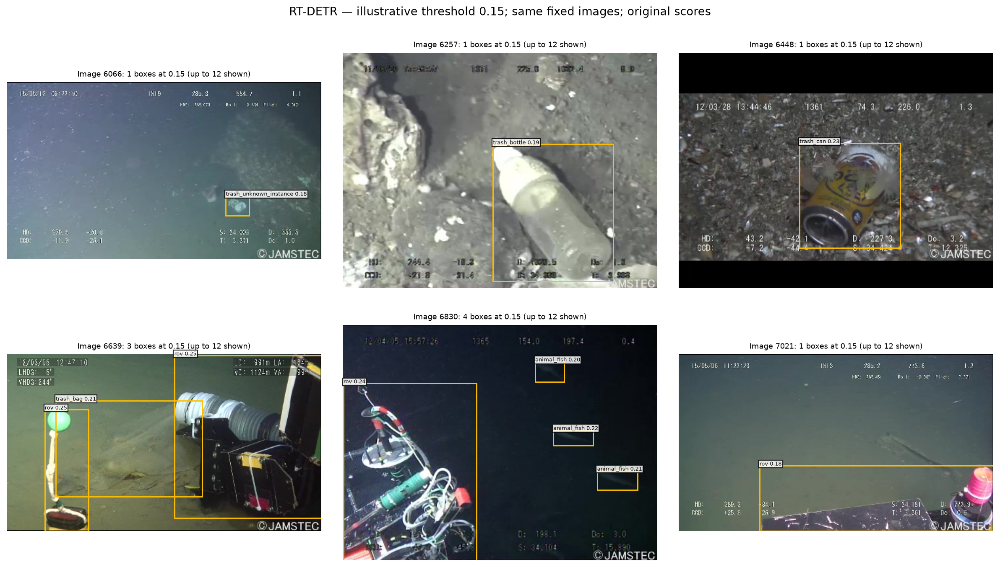

In [ ]:
show_original_code('cell-040')
show_saved_cell('cell-040')

### What we learn from moving the cutoff
At threshold **0.10**, RT-DETR has about **72.38% precision and 69.17% recall**. At **0.15**, precision
increases to **82.45%**, but recall falls to **63.52%**. The latter setting gives 1,644 matched objects,
350 false positives and 944 missed annotations at IoU 0.50. These are errors at one operating point,
not a universal error rate. Choosing the higher cutoff trades more misses for fewer false alarms.

The 0.15 pictures are an illustrative way to see the model's predictions. The grid-selected values
above are exploratory: we chose them using the same validation set on which we report F1. They are
not unbiased test results or calibrated probabilities. For a real application, we would agree on
the cost of a missed object versus a false alarm, select a cutoff on development data and freeze it
before testing on new videos. We would also investigate the low score range rather than assuming
that a lower threshold fixes every possible issue.

On this grid, RT-DETR's highest F1 is **0.718 at threshold 0.13**. The decay Faster R-CNN reaches
**0.741 at 0.71**, and the repeat-sampling model also reaches about **0.741**, at 0.79. RT-DETR's
higher COCO AP therefore does not make it the winner on every metric. AP averages classes and
several overlap requirements; this F1 uses object-level counts and only IoU 0.50. The two CNN F1
values are effectively tied here, and we should not rank them using tiny decimal differences.

In the fixed examples, the bottle in image 6257 and the can in image 6448 are visible in the
0.15 predictions. However, the annotated plant around the can is missing from that display.
Image 7021 shows the ROV box but misses the annotated unknown debris. Image 6830 shows the three
annotated fish in a dark scene. These examples show useful detections alongside misses; lowering
the cutoff does not make every object correct. They also remind us that this dataset includes
non-debris classes, so a good overall score is not the same as a good debris-only retrieval system.


# 11. Integrated Results and Error Analysis

## 11.1 Final checkpoints, selected checkpoints and controlled contrasts
The final-checkpoint table is the primary result. The best-checkpoint table is validation-selected
and therefore optimistically selected on this same development set. Missing runs remain visible
in the status table. Do not silently exclude a failed experiment from the study narrative.


### run status

,run,status
0,01_faster_constant,complete
1,02_faster_decay,complete
2,03_faster_balanced,complete
3,04_mask_decay,complete
4,05_rtdetr,complete


### final comparison

,model,AP,AP50,AP75,precision_at_05,recall_at_05,F1_at_05
0,Faster: constant LR,40.456,61.816,44.929,0.708,0.717,0.712
1,Faster: LR decay,43.923,64.116,48.449,0.727,0.723,0.725
2,Faster: repeat sampling,43.767,63.625,48.154,0.720,0.719,0.720
3,Mask: LR decay,43.960,63.688,49.235,0.713,0.723,0.718
4,RT-DETR,45.752,61.891,50.853,0.000,0.000,0.000


### Resource and exposure comparison (evaluation includes metric computation)

,model,parameters_millions,trainable_millions,peak_gpu_gb,image_presentations,validation_seconds
0,Faster: constant LR,104.487,104.062,6.201,40000,75.422
1,Faster: LR decay,104.487,104.062,6.201,40000,74.776
2,Faster: repeat sampling,104.487,104.062,6.204,40000,75.360
3,Mask: LR decay,107.116,106.690,6.233,40000,99.587
4,RT-DETR,42.772,42.772,4.252,71232,35.705


### controlled contrasts

,comparison,baseline,variant,AP_change_points
0,Learning-rate schedule,01_faster_constant,02_faster_decay,3.467
1,Repeat-factor sampling,02_faster_decay,03_faster_balanced,-0.156
2,Mask branch plus mask supervision,02_faster_decay,04_mask_decay,0.037


### per class AP

,category,Faster: constant LR,Faster: LR decay,Faster: repeat sampling,Mask: LR decay,RT-DETR
0,rov,74.182,76.163,75.842,75.518,78.771
1,plant,33.505,38.629,40.558,34.122,40.185
2,animal_fish,28.760,31.063,29.686,32.391,27.665
3,animal_starfish,36.089,39.967,38.317,38.658,36.772
4,animal_shells,21.765,25.596,25.004,23.104,31.876
5,animal_crab,17.867,21.982,18.339,21.524,10.201
6,animal_eel,27.457,39.282,38.383,39.545,36.694
7,animal_etc,33.927,33.262,34.001,34.575,37.883
8,trash_clothing,25.901,24.417,29.039,28.350,35.434
9,trash_pipe,61.742,64.095,56.485,63.766,86.561


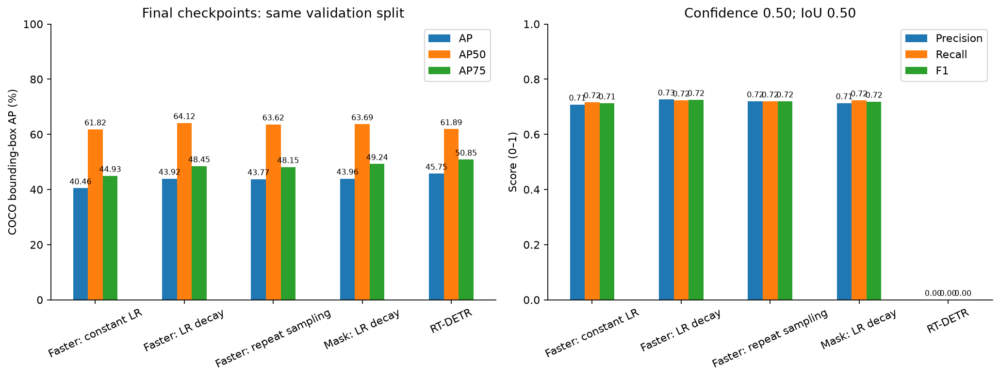

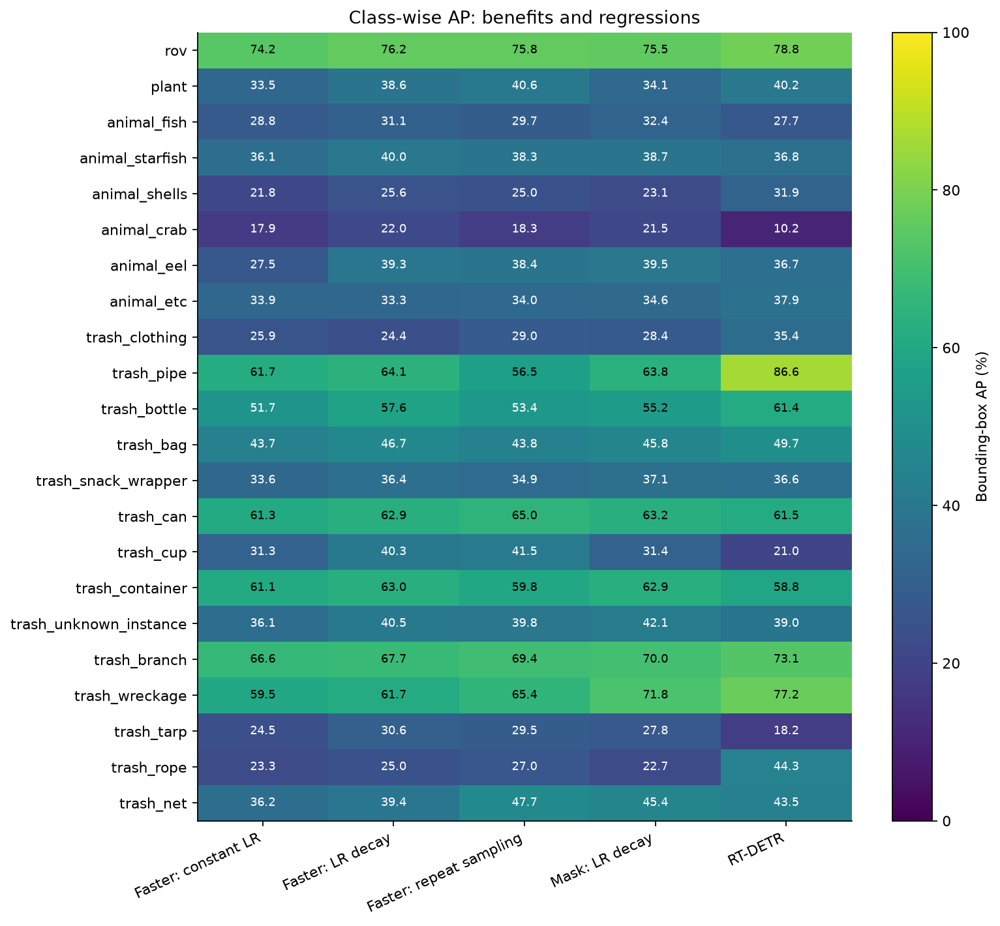

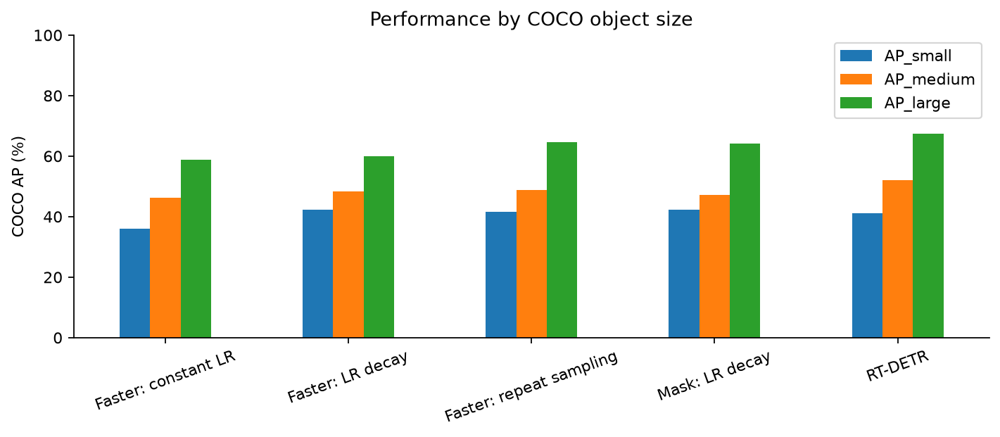

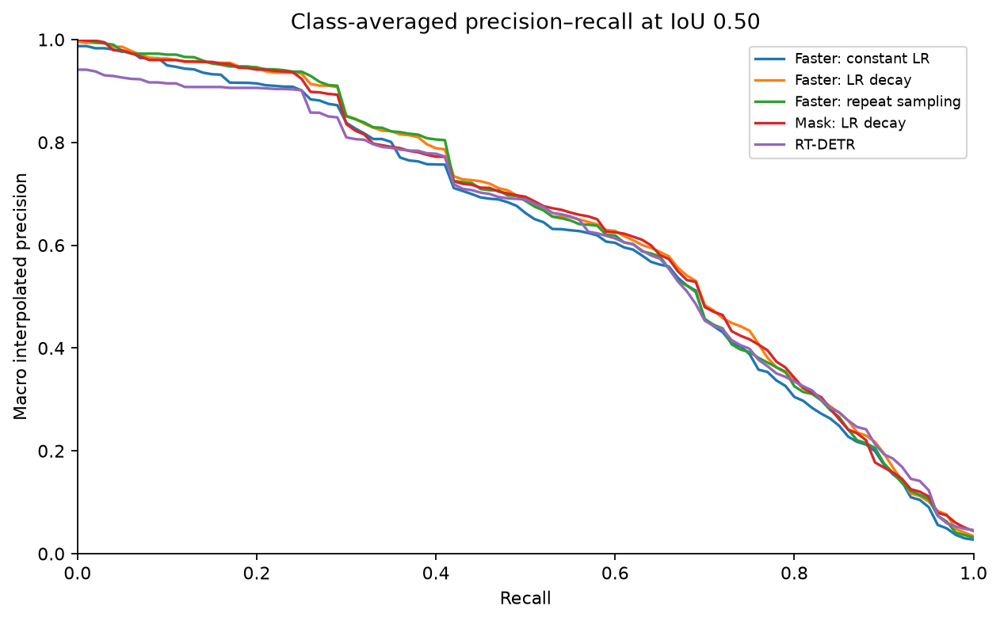

In [ ]:
show_original_code('cell-043')
show_saved_cell('cell-043')

### 11.1 Reading the comparison together
The learning-rate schedule gave the clearest clean-AP gain among our matched changes. Repeat
sampling changed which classes did well, without improving the overall clean score. The mask task
added a useful output but almost no overall box-AP gain. RT-DETR had the highest overall AP in a
broader system comparison.

The precision-recall curves and the fixed-threshold table answer different questions. The curves
summarize how predictions rank as the threshold moves. The 0.50 table describes one specific cutoff.
Using the same number as a cutoff does not give different models the same recall or error cost.
Our threshold diagnostics make this visible instead of hiding the zero-recall RT-DETR result.

### 11.2 Looking at examples and errors
The six example image IDs were fixed before we examined predictions. Green boxes in the data section
are annotations; yellow boxes in the model sections are predictions. Compare the same image across
models, then check the labels and box boundaries. A box on a real object can still be a false positive
if its class or overlap is wrong. A missing box may reflect the threshold, rather than no learned signal.

The original panels use 0.50 and show at most 12 boxes per image. A separate RT-DETR panel uses
0.15, clearly labelled as an illustrative validation choice. It does not replace the original metric.
These few images help us read the outputs but cannot establish how often each visual failure occurs.
The FP/FN counts provide a broader check at the specified IoU and threshold.

### 11.3 What the earlier TTA experiment tells us
Earlier, using multiple scales and flips with the same Faster weights increased AP from about
33.80 to 35.69 (+1.89 points), with about 3.36 times the forward-pass cost. This shows that an
inference change can help without retraining. Its checkpoint and recipe differ from the new runs,
so we keep that result outside the matched comparison. A future TTA test should reuse one of our
current checkpoints and measure the additional computation under controlled conditions.



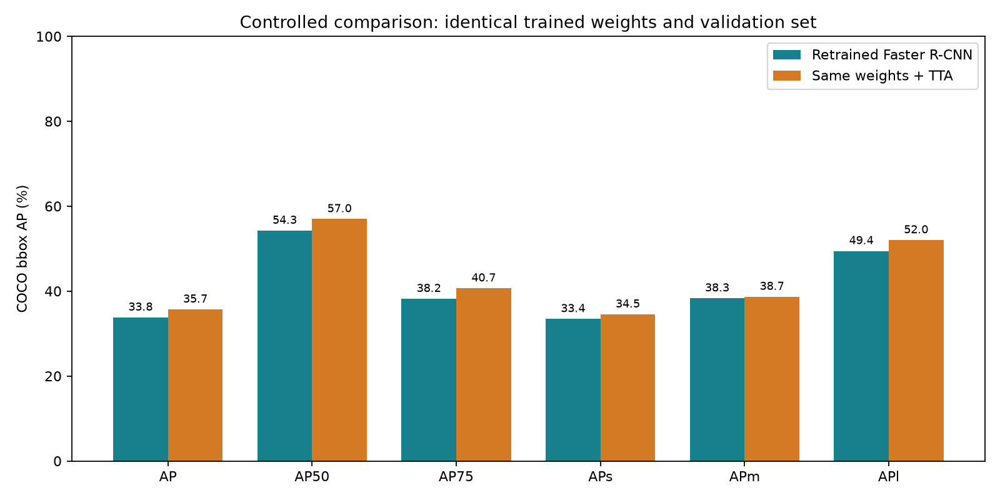

In [ ]:
show_original_code('cell-045')
show_saved_cell('cell-045')

## 11.4 New official-split corruption benchmark

After training, the queue loads the **final** checkpoint of each new run and evaluates clean images,
Gaussian blur (kernel 9, sigma 2), brightness factor 0.55 and Gaussian noise (standard deviation 0.08
in the [0,1] RGB range). A fixed 128-image official-validation subset is selected by rare-class
coverage followed by evenly spaced fill, before inspecting predictions. Smoke mode uses eight images.
No model is selected using its corrupted-input score.

Every model receives identical corrupted RGB pixels before its own preprocessing. The benchmark
stores pixel hashes and checks equality across models. Results, checkpoint hashes and subset IDs
are saved in `outputs/<suite>/robustness/`. Interrupted evaluation resumes completed conditions.
The historical and new subsets differ, so their robustness tables remain separate.

### What the measures mean
- **Absolute corrupted AP:** detection performance under the specified degradation.
- **AP change in percentage points:** corrupted AP minus clean AP on this same subset.
- **AP retention:** 100 × corrupted AP / clean subset AP; undefined if the denominator is zero.

There is no combined “AI score”. Retention can favor a weak baseline and can exceed 100%.
Synthetic corruption at one severity is neither adversarial robustness nor a new-camera test.


def corrupt(image, condition, image_id, seed):
    """Identical RGB uint8 pixels are delivered to every model's own processor."""
    x = TF.pil_to_tensor(image).float()/255
    if condition == 'gaussian_blur':
        x = TF.gaussian_blur(x, [9,9], [2.,2.])
    elif condition == 'low_brightness':
        x = TF.adjust_brightness(x, .55)
    elif condition == 'gaussian_noise':
        generator = torch.Generator().manual_seed(seed + int(image_id)*1009)
        x = (x + torch.randn(x.shape, generator=generator)*.08).clamp(0,1)
    elif condition != 'clean':
        raise ValueError(condition)
    return TF.to_pil_image((x*255).round().to(torch.uint8))

,run,model,clean_AP,mean_corrupted_AP,mean_retention_percent,worst_corrupted_AP
0,01_faster_constant,Faster: constant LR,40.316,27.518,68.256,22.055
1,02_faster_decay,Faster: LR decay,44.637,27.541,61.701,20.822
2,03_faster_balanced,Faster: repeat sampling,43.654,29.494,67.562,22.577
3,04_mask_decay,Mask: LR decay,43.965,27.693,62.988,20.290
4,05_rtdetr,RT-DETR,44.471,35.743,80.373,30.977


,model,condition,AP,AP_change_points,retention_percent
0,Faster: constant LR,clean,40.316,0.000,100.000
1,Faster: constant LR,gaussian_blur,24.143,-16.173,59.884
2,Faster: constant LR,low_brightness,36.357,-3.959,90.179
3,Faster: constant LR,gaussian_noise,22.055,-18.261,54.705
4,Faster: LR decay,clean,44.637,0.000,100.000
5,Faster: LR decay,gaussian_blur,21.639,-22.998,48.478
6,Faster: LR decay,low_brightness,40.163,-4.474,89.978
7,Faster: LR decay,gaussian_noise,20.822,-23.815,46.648
8,Faster: repeat sampling,clean,43.654,0.000,100.000
9,Faster: repeat sampling,gaussian_blur,25.249,-18.406,57.838


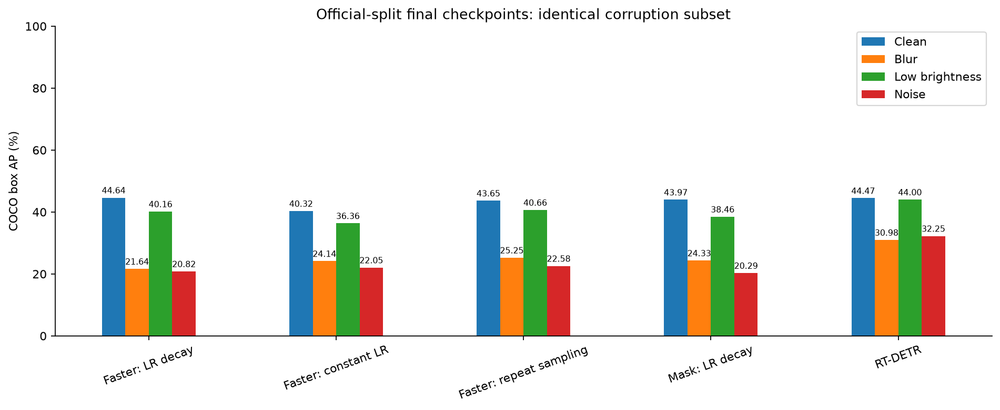

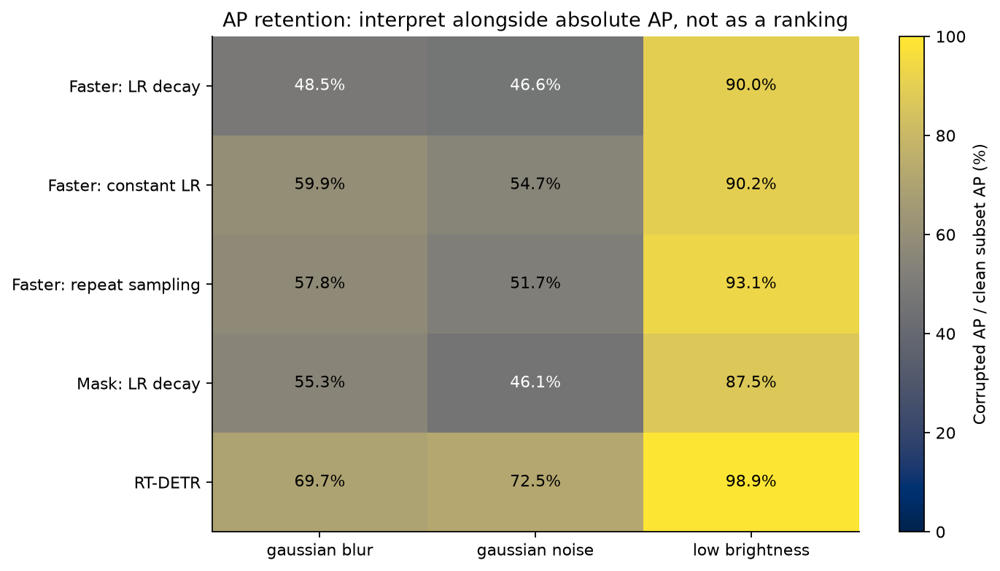

In [ ]:
show_original_code('cell-047')
show_saved_cell('cell-047')

### 11.4 What happened under image corruption?
RT-DETR had **35.74 mean corrupted AP**, compared with **29.49** for the best CNN on this measure
(repeat sampling). Its retention was **80.37%**, versus 67.56% for that CNN. These figures use the
same 128 images and identical corrupted pixels before each model's own preprocessing.

Blur and noise were harder than reduced brightness. RT-DETR obtained 30.98 AP under blur and
about 32.25 under noise, compared with 44.47 on clean subset images. Its low-light AP was about
44.00. We should not interpret one brightness factor as a test of all underwater lighting conditions.

The repeat sampler increased mean corrupted AP from **27.54 to 29.49** relative to the decay
baseline, despite the small drop in full clean-validation AP. That is a useful trade-off if the
application expects degraded images. The result does not show why it happened; the selected images,
class mix and training variation may contribute.

Retention alone can be misleading. The constant-LR model retained a larger percentage than the
decay model, yet their mean corrupted AP values were almost identical (27.52 and 27.54).
We therefore report absolute AP beside retention. We compare each corrupted result with its own
clean **subset** result, not with AP over all 1,147 validation images.

This is a small, deliberately class-covering subset at one severity per corruption. It is a stress
test, not evidence that the model will generalize to a new ocean or camera. A stronger follow-up
would vary severity and use held-out videos recorded under real poor-visibility conditions.

## 11.5 Imported Grad-CAM examples: explanation is not a performance score
The following results come from the earlier custom-split experiments. Their heatmaps use the final
ResNet stage on eight fixed images. The target sums strong scores whose predicted classes appear
in the annotations, with a fallback to the strongest scores. We use them as an example of how an
explanation method can be inspected. They are not heatmaps from the five new models.



,model,clean_subset_AP_percent,mean_corrupted_AP_percent,mean_AP_retention_percent,mean_cam_cosine_similarity
0,Faster R-CNN (3 ep),10.903,7.505,68.831,0.500
1,Mask R-CNN (3 ep),12.149,8.131,66.926,0.661
2,RetinaNet (3 ep),4.258,3.416,80.222,0.800
3,RetinaNet (12 ep),7.511,4.720,62.837,0.592
4,RetinaNet balanced (12 ep),8.231,5.842,70.975,0.532


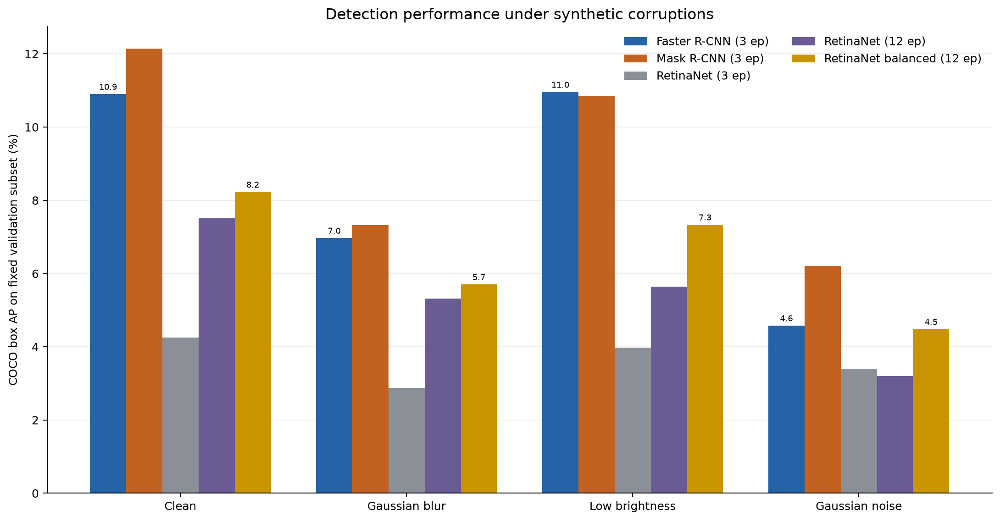

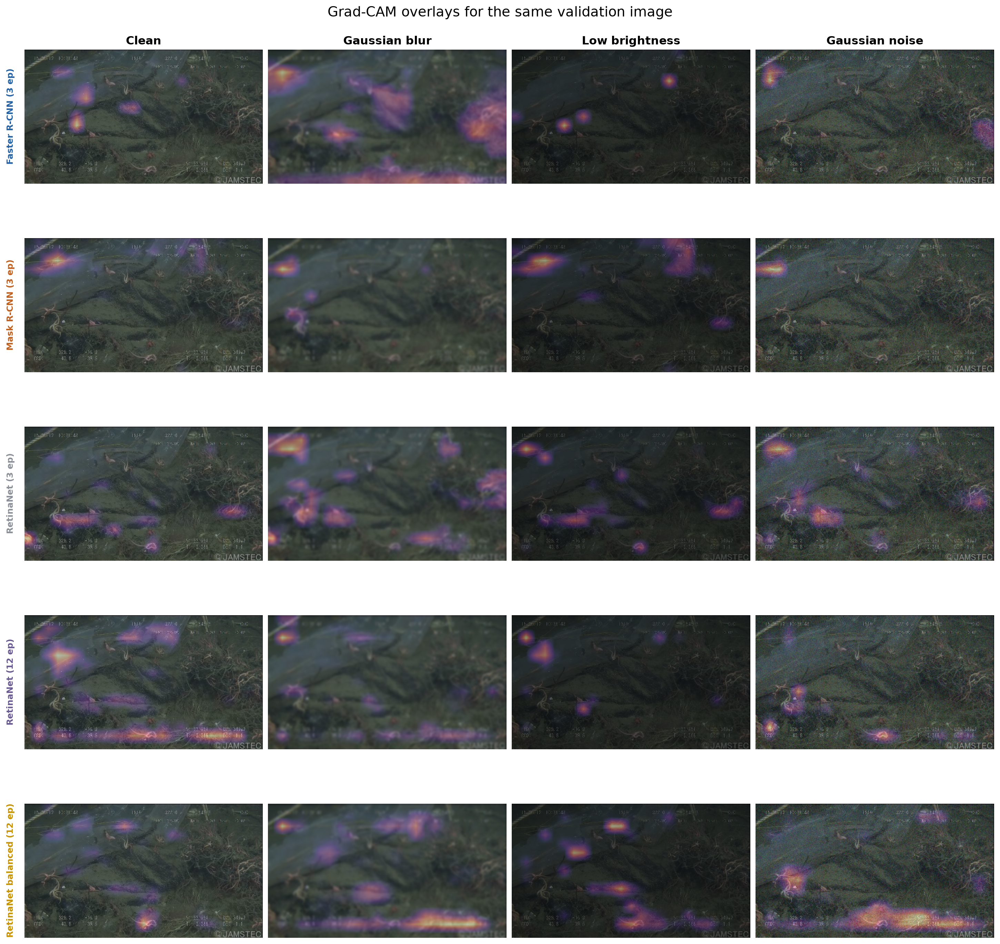

In [ ]:
show_original_code('cell-049')
show_saved_cell('cell-049')

### Interpretation and limitations of these heatmaps
The historical three-epoch RetinaNet has the highest mean CAM cosine similarity (about 0.800)
but the lowest mean corrupted AP (about 3.42%). A stable attribution map therefore does not imply
accurate detection. The historical Mask R-CNN has the highest absolute mean corrupted AP (8.13%)
within that benchmark; this does not rank it against the new official-split models.

**Additional methodological caveat:** high-scoring targets are selected again after each corruption.
The selected object or category can change, so map similarity mixes input sensitivity with target
selection changes. The target uses ground-truth categories for an offline diagnostic; it is not a
deployment-time correctness estimator. A stronger follow-up would fix a class/object target across
conditions and use deletion/insertion or other faithfulness checks. Eight selected images and one
layer cannot support population-wide or causal explanations.

Reference: Selvaraju et al., [Grad-CAM](https://arxiv.org/abs/1610.02391).


# 12. Discussion, Limitations and Next Steps

## 12.1 What we learned
Our starting question was whether the low short-run result meant that the task or model was unsuitable.
The longer official-split experiments show that this would have been an early conclusion. The new
constant-LR baseline reached 40.46 AP, and a learning-rate schedule raised it to 43.92. Earlier custom
split results are not directly comparable with these numbers, so we do not report their difference
as a training gain.

The more useful lesson is that different changes solve different problems. Repeating uncommon images
helped some classes and the corruption benchmark, but did not raise clean overall AP. Mask supervision
produced segmentation output without a meaningful overall box-AP advantage. RT-DETR achieved the best
overall AP and corrupted-image AP, but needed a different confidence cutoff and had a different budget.

For this measured setup, we would use decay Faster R-CNN as a clear box-detection reference. RT-DETR
is a promising next candidate, after checking its confidence behavior on independent data. If masks
are part of the application, Mask R-CNN is the relevant option even though box AP is similar.

## 12.2 What the results cannot establish
We used one seed, and very small differences may be training variation. The official split shares
113 source videos across training and validation, so neighbouring frames may be similar. We reused
validation for development, checkpoint selection and threshold exploration. None of these results
is an untouched test estimate for unseen videos.

RT-DETR and the CNN models differ in several settings. Masks also require extra annotations.
We cannot separate all these effects with five runs. Rare classes have limited validation examples,
and the 22-class average includes marine life and ROV objects as well as debris.

The computer was also used for gaming during the run. Recorded times describe that session, not a
fair speed benchmark. Validation time includes preprocessing and metric computation. We compare
parameter counts, but do not claim a deployment speed winner from these timings.

## 12.3 What we would try next, and why
| Priority | Experiment | What it would answer |
|---|---|---|
| 1 | Fix a video-disjoint train/development/test split before further tuning | Does performance transfer to unseen videos? |
| 2 | Repeat constant versus decay LR with several seeds | Is the largest matched gain reliable? |
| 3 | Select RT-DETR's threshold on development data, then freeze it for testing | Can it meet an explicit precision/recall requirement? |
| 4 | Test one smaller repeat factor or targeted augmentation | Can rare-class gains be kept without the observed regressions? |
| 5 | Compare a higher input resolution at a fixed documented budget | Can small-object AP improve enough to justify the cost? |
| 6 | Extend RT-DETR training with validation monitoring | Are its late AP gains and low scores a training-duration issue? |

These are proposed experiments, not results we already obtained. We would change one main factor
at a time and save the configuration, seed, predictions and evaluation outputs. Adding more model
names alone would not make the comparison more informative.

## 12.4 Experimental Summary

Longer training and learning-rate decay gave the clearest improvements in our matched CNN
experiments. Repeat sampling changed class-level performance, while mask supervision added
segmentation output. RT-DETR achieved the highest overall AP in the new study, although its
training recipe and exposure differed. These comparisons show why model choice depends on the
metric and the intended use, rather than one score alone.

## References
1. Hong, Fulton & Sattar (2020). [TrashCan](https://arxiv.org/abs/2007.08097).
2. Ren et al. (2015). [Faster R-CNN](https://arxiv.org/abs/1506.01497).
3. He et al. (2017). [Mask R-CNN](https://arxiv.org/abs/1703.06870).
4. Carion et al. (2020). [DETR](https://arxiv.org/abs/2005.12872).
5. Zhao et al. (2024). [RT-DETR](https://arxiv.org/abs/2304.08069).
6. [Detectron2 source](https://github.com/facebookresearch/detectron2).
7. [Hugging Face RT-DETR documentation](https://huggingface.co/docs/transformers/model_doc/rt_detr).
8. [Pinned pretrained model](https://huggingface.co/PekingU/rtdetr_r50vd/tree/6b983e977d71d9047055aafff2ff215191021ee3).
9. [COCO evaluation implementation](https://github.com/cocodataset/cocoapi).
